# Point-of-sale and cash loan balances: EDA and feature engineering

This notebook studies `POS_CASH_balance.csv`, a month-by-month record of the state of each applicant's earlier point-of-sale and cash loans with Home Credit, and turns it into features, one row per applicant.

It follows the method of notebooks 03, 05 and 07. Those three tables took the model's cross-validated ROC AUC from 0.7685 to 0.7932, and its Kaggle private score from 0.7638 to 0.7934.

## Why this table

Notebook 07 found one thing the payment record cannot show. It records payments that were made, so an instalment that fell due and was not paid mostly has no row at all, and missed payments are largely invisible. This table is built the other way. It has a row for every month of every loan, whether or not anything was paid, and two of its columns count the days past due in that month. If an applicant fell behind, it should be here.

```
application (1 row per applicant)
   ├── bureau (credits at other lenders)                                   <- done, notebooks 03 and 04
   └── previous_application (earlier applications to Home Credit)          <- done, notebooks 05 and 06
          ├── installments_payments   (each payment made)                  <- done, notebooks 07 and 08
          ├── POS_CASH_balance        (monthly state of cash and point-of-sale loans)   <- this notebook
          └── credit_card_balance     (monthly state of credit cards)
```

The table also looks like `bureau_balance`, the monthly status of bureau credits, which notebook 03 left out because it is supplied on different terms in train and test: present for a third of credits in train and nearly all of them in test. A monthly table that a lender keeps for its own loans may not have that problem, but the question has to be asked first. Notebook 05 ran the supply test on this table and it passed. Stage 1 runs it again in more detail.

## Inputs

| File | Rows | One row is | Key |
|---|---:|---|---|
| `data/raw/POS_CASH_balance.csv` | about 10 million | One month of one earlier loan | `SK_ID_PREV` and `MONTHS_BALANCE` |
| `data/raw/previous_application.csv` | about 1.7 million | One earlier application | `SK_ID_PREV` |
| `data/processed/installments_*_features.parquet` | 307,511 and 48,744 | The payment features of notebook 07 | `SK_ID_CURR` |
| `data/processed/application_split.parquet` | 307,511 | The frozen development and holdout split | `SK_ID_CURR` |

## What this notebook does

| # | Stage | Question it answers |
|---|---|---|
| 1 | Structure and keys | What is one row, how do the tables link, and is the table supplied on the same terms in train and test? |
| 2 | Coverage and target | Do applicants with no rows here default at a different rate? |
| 3 | Column-by-column audit | Is each value believable, and is each column supplied on the same terms? |
| 4 | Time audit | Does any row describe something after the current application? |
| 5 | Signal | Which kinds of month relate to default, and is any of it new beside the payment record? |
| 6 | Aggregation design | Which summaries per applicant are worth building? |
| 7 | Candidate features | Build them for train and test, and verify them by an independent calculation |
| 8 | Screening | Shift, redundancy, and signal beyond the current model |
| 9 | Save | Write the feature tables and verify them from disk |

## Rules followed throughout

The rules of the earlier feature notebooks, unchanged.

- **The holdout stays closed.** Whenever this notebook looks at `TARGET`, it uses the 246,008 development applicants only.
- **A feature uses only the applicant's own rows.** No summary is computed across applicants.
- **Nothing is learned from the target here.**
- **Only information available at the application date is used.** Stage 4 checks every date, and in this table that question has a specific form, below.
- **Every column is audited twice:** is the value believable, and is it supplied on the same terms in train and test?
- **Rare events are judged by what they do for the applicants they describe,** not by a score, and not by how serious they sound. Notebook 08 found a rare-event feature that described very risky applicants and still added nothing.

## What is different about this table

- **It overlaps with what the model has.** The loans here are the loans whose payments notebook 07 summarised, and notebook 08's model already has 23 features from them. The question is not whether this table relates to default, which it surely does, but whether it says anything the payment record did not. Stage 5 asks that directly, beside the payment features, before anything is built.
- **The month of the application.** The dictionary says `MONTHS_BALANCE` of -1 is the freshest monthly snapshot and 0 is the information at the application, often the same. If month 0 exists and is filled differently in train and test, it is the `bureau_balance` problem again. If it describes the month in which the current loan was granted, it may describe the future.
- **Days past due may be the missing piece.** If this table records arrears that the payment table cannot, it is where the applicants notebook 08 under-predicted would show.

## What this notebook produces

- Cleaning rules for `POS_CASH_balance`.
- A feature table, one row per applicant, for train and test, saved under `data/processed/`.
- A module under `src/features/`.

## Out of scope

- Whether the features improve the model. That is notebook 10.
- `credit_card_balance`.

## Stage 1: Structure and keys

What is in `POS_CASH_balance.csv`, what one row is, how the table links to the tables above it, and whether it is supplied on the same terms in train and test.

No target is used in this stage.

In [1]:
import gc, sys, time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

SEED = 42
RAW = '../data/raw'
PROCESSED = '../data/processed'

started = time.time()
pos = pd.read_csv(f'{RAW}/POS_CASH_balance.csv')
print(f"POS_CASH_balance.csv: {pos.shape[0]:,} rows, {pos.shape[1]} columns, {pos.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory, read in {time.time() - started:.1f} seconds")
pos.head(5)

POS_CASH_balance.csv: 10,001,358 rows, 8 columns, 702 MB in memory, read in 5.2 seconds


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0


### 1.1 Columns and types

The descriptions come from `HomeCredit_columns_description.csv`.

In [2]:
LOAN, MONTH = 'SK_ID_PREV', 'MONTHS_BALANCE'
descriptions = pd.read_csv(f'{RAW}/HomeCredit_columns_description.csv', encoding='latin-1')
described = descriptions[descriptions['Table'] == 'POS_CASH_balance.csv'].assign(Row=lambda d: d['Row'].str.strip()).drop_duplicates('Row').set_index('Row')['Description']
overview = pd.DataFrame({
    'dtype': pos.dtypes.astype(str),
    'missing': pos.isna().sum(),
    'missing_pct': pos.isna().mean() * 100,
    'distinct': pos.nunique(),
    'min': pos.min(numeric_only=True),
    'median': pos.median(numeric_only=True),
    'max': pos.max(numeric_only=True),
})
print(overview.to_string(float_format=lambda v: f'{v:,.3f}'))
print()
for c in pos.columns:
    print(f"{c}: {described.get(c, 'no description')}")
print('\ncontract status, all rows:')
print(pos['NAME_CONTRACT_STATUS'].value_counts(dropna=False).to_string())
whole = {c: bool((pos[c].dropna() % 1 == 0).all()) for c in ['CNT_INSTALMENT', 'CNT_INSTALMENT_FUTURE']}
print(f"\nwhole numbers only: {whole}")

                         dtype  missing  missing_pct  distinct           min        median           max
CNT_INSTALMENT         float64    26071        0.261        73         1.000        12.000        92.000
CNT_INSTALMENT_FUTURE  float64    26087        0.261        79         0.000         7.000        85.000
MONTHS_BALANCE           int64        0        0.000        96       -96.000       -28.000        -1.000
NAME_CONTRACT_STATUS       str        0        0.000         9           NaN           NaN           NaN
SK_DPD                   int64        0        0.000      3400         0.000         0.000     4,231.000
SK_DPD_DEF               int64        0        0.000      2307         0.000         0.000     3,595.000
SK_ID_CURR               int64        0        0.000    337252   100,001.000   278,654.000   456,255.000
SK_ID_PREV               int64        0        0.000    936325 1,000,001.000 1,896,565.000 2,843,499.000

SK_ID_PREV: ID of previous credit in Home Credit relat


whole numbers only: {'CNT_INSTALMENT': True, 'CNT_INSTALMENT_FUTURE': True}


### 1.2 What is one row?

The natural guess is one month of one loan: `SK_ID_PREV` and `MONTHS_BALANCE` together. This section tests it, and looks at whether each loan's months run without a gap.

In [3]:
key_checks = {
    'no missing value in either key or the month': bool(pos[[LOAN, 'SK_ID_CURR', MONTH]].notna().all().all()),
    'no fully duplicated row': int(pos.duplicated().sum()) == 0,
    'every loan belongs to one applicant': int(pos.groupby(LOAN)['SK_ID_CURR'].nunique().max()) == 1,
    'loan and month identify a row': not pos.duplicated([LOAN, MONTH]).any(),
}
for name, ok in key_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
twins = pos.duplicated([LOAN, MONTH], keep=False)
print(f"rows sharing a loan and month with another row: {int(twins.sum()):,} ({twins.mean():.4%})")
if twins.any():
    example = pos[twins].sort_values([LOAN, MONTH]).head(6)
    print(example.to_string(index=False))

loans = pos.groupby(LOAN).agg(applicant=('SK_ID_CURR', 'first'), rows=(MONTH, 'size'), months=(MONTH, 'nunique'), first_month=(MONTH, 'min'), last_month=(MONTH, 'max'))
loans['span'] = loans['last_month'] - loans['first_month'] + 1
loans['missing_months'] = loans['span'] - loans['months']
print(f"\nloans: {len(loans):,}; months per loan: median {loans['months'].median():.0f}, 99th percentile {loans['months'].quantile(0.99):.0f}, most {loans['months'].max()}")
print(f"loans whose months run without a gap: {(loans['missing_months'] == 0).mean():.2%}; share of months missing inside a loan's span: {loans['missing_months'].sum() / loans['span'].sum():.3%}")
print(f"file is sorted by applicant: {bool(pos['SK_ID_CURR'].is_monotonic_increasing)}; by loan: {bool(pos[LOAN].is_monotonic_increasing)}")

PASS  no missing value in either key or the month
PASS  no fully duplicated row
PASS  every loan belongs to one applicant
PASS  loan and month identify a row


rows sharing a loan and month with another row: 0 (0.0000%)



loans: 936,325; months per loan: median 10, 99th percentile 33, most 96
loans whose months run without a gap: 99.79%; share of months missing inside a loan's span: 0.069%
file is sorted by applicant: False; by loan: False


### 1.3 Link to the application table

In [4]:
split = pd.read_parquet(f'{PROCESSED}/application_split.parquet')
TEST_IDS = pd.read_parquet(f'{PROCESSED}/application_test_features.parquet', columns=[]).index
DEV_IDS, HOLDOUT_IDS = split.index[split['split'] == 'dev'], split.index[split['split'] == 'holdout']
TRAIN_IDS = split.index
assert (len(DEV_IDS), len(HOLDOUT_IDS), len(TEST_IDS)) == (246008, 61503, 48744) and len(TRAIN_IDS.intersection(TEST_IDS)) == 0
PARTS = {'train: development': DEV_IDS, 'train: holdout': HOLDOUT_IDS, 'test': TEST_IDS}

part_of = pd.Series('neither file', index=pd.Index(pos['SK_ID_CURR'].unique(), name='SK_ID_CURR'))
for label, ids in PARTS.items():
    part_of[part_of.index.isin(ids)] = label
pos_part = pos['SK_ID_CURR'].map(part_of)
rows_per_applicant = pos.groupby('SK_ID_CURR').size()
loans_per_applicant = pos.groupby('SK_ID_CURR')[LOAN].nunique()
coverage = {}
for label, ids in PARTS.items():
    counts = rows_per_applicant.reindex(ids).fillna(0)
    coverage[label] = {'applicants': len(ids), 'with_rows': int((counts > 0).sum()), 'with_rows_pct': (counts > 0).mean() * 100, 'rows': int((pos_part == label).sum()),
                       'rows_if_any_median': counts[counts > 0].median(), 'loans_if_any_mean': loans_per_applicant.reindex(ids).dropna().mean()}
print(pd.DataFrame(coverage).T.to_string(float_format=lambda v: f'{v:,.2f}'))
print(f"\napplicants here that are in neither application file: {int((part_of == 'neither file').sum()):,}")

inst_train = pd.read_parquet(f'{PROCESSED}/installments_train_features.parquet', columns=['INST_N_INSTALMENTS'])
inst_test = pd.read_parquet(f'{PROCESSED}/installments_test_features.parquet', columns=['INST_N_INSTALMENTS'])
has_payments = pd.concat([inst_train, inst_test])['INST_N_INSTALMENTS'].notna()
has_pos = pd.Series(has_payments.index.isin(rows_per_applicant.index), index=has_payments.index)
print('\napplicants in train and test by whether they have rows here and a payment history (% of all):')
print((pd.crosstab(has_pos.map({True: 'rows in POS_CASH_balance', False: 'none'}), has_payments.map({True: 'payment history', False: 'no payment history'}), normalize='all') * 100).round(2).to_string())

                    applicants  with_rows  with_rows_pct         rows  rows_if_any_median  loans_if_any_mean
train: development  246,008.00 231,556.00          94.13 6,834,611.00               22.00               2.77
train: holdout       61,503.00  57,888.00          94.12 1,708,764.00               22.00               2.76
test                 48,744.00  47,808.00          98.08 1,457,983.00               23.00               2.84

applicants here that are in neither application file: 0

applicants in train and test by whether they have rows here and a payment history (% of all):
INST_N_INSTALMENTS        no payment history  payment history
row_0                                                        
none                                    4.53             0.80
rows in POS_CASH_balance                0.15            94.52


### 1.4 Link to `previous_application`, and the supply test

Every loan here should be an approved application in `previous_application`, of a kind that has a schedule: a cash loan or a consumer (point-of-sale) loan. And for the bureau's monthly table, notebook 03 found the deciding fact was not in any column but in which credits had rows at all. So the share of each applicant's approved loans that appear here is compared between train and test.

In [5]:
sys.path.insert(0, '../src/features')
from previous_application import clean_previous

prev = clean_previous(pd.read_csv(f'{RAW}/previous_application.csv'))
prev_ids = prev.set_index('SK_ID_PREV')
loans['in_prev'] = loans.index.isin(prev_ids.index)
loans['part'] = loans['applicant'].map(part_of)
print(f"loans with monthly rows: {len(loans):,}; found in previous_application after cleaning: {loans['in_prev'].mean():.2%}")
print('found, by part (%):', (loans.groupby('part')['in_prev'].mean() * 100).round(2).to_dict())
missing = loans[~loans['in_prev']]
print(f"not found: {len(missing):,} loans, {int(missing['rows'].sum()):,} rows ({missing['rows'].sum() / len(pos):.2%}); their median first month {missing['first_month'].median():.0f}, others {loans.loc[loans['in_prev'], 'first_month'].median():.0f}")
found = loans[loans['in_prev']].join(prev_ids[['NAME_CONTRACT_STATUS', 'NAME_CONTRACT_TYPE']].rename(columns={'NAME_CONTRACT_STATUS': 'application_status'}))
print('status of the application behind each loan:', found['application_status'].value_counts().to_dict())
print('contract type:', found['NAME_CONTRACT_TYPE'].value_counts().to_dict())

approved = prev[(prev['NAME_CONTRACT_STATUS'] == 'Approved')].copy()
approved['has_rows'] = approved['SK_ID_PREV'].isin(loans.index)
approved['part'] = approved['SK_ID_CURR'].map(lambda i: None)
for label, ids in PARTS.items():
    approved.loc[approved['SK_ID_CURR'].isin(ids), 'part'] = label
known = approved[approved['part'].notna()]
print(f"\napproved earlier applications of train and test applicants: {len(known):,}; with monthly rows here: {known['has_rows'].mean():.2%}")
print(pd.crosstab(known['NAME_CONTRACT_TYPE'], known['part'], values=known['has_rows'], aggfunc='mean').mul(100).round(2).to_string())
age = pd.cut(-known['DAYS_DECISION'] / 365.25, [0, 1, 2, 4, 6, 8, 100], labels=['under 1 year', '1 to 2', '2 to 4', '4 to 6', '6 to 8', 'over 8'])
print('\nshare of approved applications with monthly rows, by how long ago the decision was (%):')
print(pd.crosstab(age, known['part'], values=known['has_rows'], aggfunc='mean').mul(100).round(2).to_string())

def supply_auc(share):
    share = share[share.index.isin(TRAIN_IDS) | share.index.isin(TEST_IDS)]
    is_test = share.index.isin(TEST_IDS).astype(int)
    a = roc_auc_score(is_test, share.values)
    return max(a, 1 - a), share[is_test == 0].mean(), share[is_test == 1].mean()

scheduled = known[known['NAME_CONTRACT_TYPE'].isin(['Cash loans', 'Consumer loans'])]
for label, subset in [('all approved applications', known), ('approved cash and consumer loans', scheduled)]:
    a, tr, te = supply_auc(subset.groupby('SK_ID_CURR')['has_rows'].mean())
    print(f"\nsupply test, {label}: share with monthly rows, train {tr:.3f}, test {te:.3f}; AUC {a:.3f}   (0.50 = supplied on the same terms; bureau_balance scored 0.82)")

# the same question against the payment table: of the loans with payments, which have monthly rows here?
inst_loans = pd.read_csv(f'{RAW}/installments_payments.csv', usecols=['SK_ID_PREV', 'SK_ID_CURR', 'NUM_INSTALMENT_VERSION']).groupby('SK_ID_PREV').agg(applicant=('SK_ID_CURR', 'first'), card=('NUM_INSTALMENT_VERSION', lambda v: (v == 0).any()))
inst_loans = inst_loans[~inst_loans['card']]
inst_loans['has_rows'] = inst_loans.index.isin(loans.index)
a, tr, te = supply_auc(inst_loans.groupby('applicant')['has_rows'].mean())
print(f"\nloans other than cards with payments on record: {len(inst_loans):,}; with monthly rows here: {inst_loans['has_rows'].mean():.2%}")
print(f"supply test, share of an applicant's paid loans with monthly rows: train {tr:.3f}, test {te:.3f}; AUC {a:.3f}")
print(f"loans with monthly rows here that have no payments on record: {(~loans.index.isin(inst_loans.index) & ~loans.index.isin(inst_loans.index)).mean():.2%}")
del inst_loans
gc.collect()

loans with monthly rows: 936,325; found in previous_application after cleaning: 96.00%
found, by part (%): {'test': 95.07, 'train: development': 96.15, 'train: holdout': 96.18}
not found: 37,480 loans, 341,182 rows (3.41%); their median first month -96, others -30
status of the application behind each loan: {'Approved': 898845}
contract type: {'Consumer loans': 610350, 'Cash loans': 288495}



approved earlier applications of train and test applicants: 1,036,647; with monthly rows here: 86.71%
part                 test  train: development  train: holdout
NAME_CONTRACT_TYPE                                           
Cash loans          92.30               92.32           92.36
Consumer loans      97.23               97.46           97.50
Revolving loans      0.00                0.00            0.00

share of approved applications with monthly rows, by how long ago the decision was (%):


part            test  train: development  train: holdout
DAYS_DECISION                                           
under 1 year   75.65               73.85           74.22
1 to 2         80.61               86.68           86.78
2 to 4         88.41               90.12           90.17
4 to 6         95.45               96.65           96.55
6 to 8         90.64               87.94           87.97



supply test, all approved applications: share with monthly rows, train 0.886, test 0.879; AUC 0.516   (0.50 = supplied on the same terms; bureau_balance scored 0.82)

supply test, approved cash and consumer loans: share with monthly rows, train 0.969, test 0.967; AUC 0.503   (0.50 = supplied on the same terms; bureau_balance scored 0.82)



loans other than cards with payments on record: 925,074; with monthly rows here: 99.99%
supply test, share of an applicant's paid loans with monthly rows: train 1.000, test 1.000; AUC 0.500
loans with monthly rows here that have no payments on record: 1.21%


20

### 1.5 The months, and the month of the application

MONTHS_BALANCE from -96 to -1



share of each part's rows in a given month (%):
                train: development  train: holdout   test
MONTHS_BALANCE                                           
 0                           0.000           0.000  0.000
-1                           0.955           0.955  0.912
-2                           1.717           1.719  1.564
-3                           1.858           1.866  1.693
-6                           2.091           2.098  1.927
-12                          2.159           2.167  2.066

each loan's last month on record, by part:
                       count  mean   std   min   10%   50%  90%  max
part                                                                
test                135988.0 -31.3  28.1 -96.0 -78.0 -23.0 -2.0 -1.0
train: development  640308.0 -29.9  27.4 -96.0 -75.0 -21.0 -1.0 -1.0
train: holdout      160029.0 -29.9  27.4 -96.0 -74.0 -21.0 -1.0 -1.0

loans whose last month is 0: 0.00%; is -1: 10.14%



applicants with rows (train and test):
                count   mean    std  min    5%   25%   50%   75%   95%    99%    max
months       337252.0  29.66  24.53  1.0   6.0  12.0  22.0  39.0  80.0  117.0  295.0
loans        337252.0   2.78   1.98  1.0   1.0   1.0   2.0   4.0   7.0   10.0   26.0
months_back  337252.0  52.87  29.69  1.0  11.0  25.0  51.0  82.0  96.0   96.0   96.0


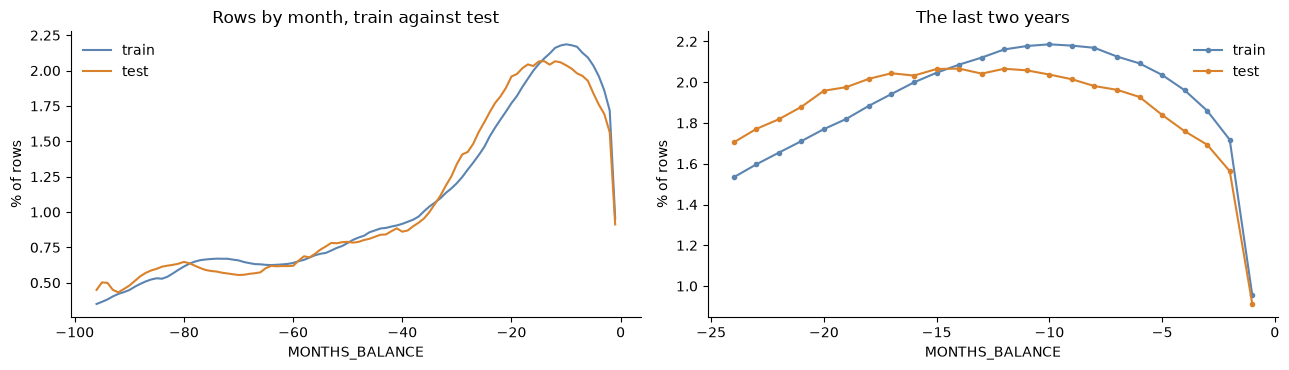

In [6]:
months = pos[MONTH]
print(f"MONTHS_BALANCE from {months.min()} to {months.max()}")
last = pd.DataFrame({label: months[pos_part == label].value_counts(normalize=True).reindex([0, -1, -2, -3, -6, -12]).fillna(0) * 100 for label in PARTS})
print('\nshare of each part\'s rows in a given month (%):')
print(last.round(3).to_string())
per_loan_last = loans.groupby('part')['last_month'].describe(percentiles=[0.1, 0.5, 0.9])
print('\neach loan\'s last month on record, by part:')
print(per_loan_last.round(1).to_string())
print(f"\nloans whose last month is 0: {(loans['last_month'] == 0).mean():.2%}; is -1: {(loans['last_month'] == -1).mean():.2%}")

per_applicant = pd.DataFrame({'months': pos.groupby('SK_ID_CURR')[MONTH].size(), 'loans': loans_per_applicant, 'months_back': -pos.groupby('SK_ID_CURR')[MONTH].min()})
known_applicants = per_applicant[per_applicant.index.isin(TRAIN_IDS) | per_applicant.index.isin(TEST_IDS)]
print('\napplicants with rows (train and test):')
print(known_applicants.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for label, ids, colour in [('train', TRAIN_IDS, '#5b84b1'), ('test', TEST_IDS, '#d9822b')]:
    m = pos['SK_ID_CURR'].isin(ids)
    share = months[m].value_counts(normalize=True).sort_index() * 100
    axes[0].plot(share.index, share.values, label=label, color=colour)
    axes[1].plot(share.loc[-24:].index, share.loc[-24:].values, marker='o', markersize=3, label=label, color=colour)
axes[0].set_xlabel('MONTHS_BALANCE'); axes[0].set_ylabel('% of rows'); axes[0].set_title('Rows by month, train against test'); axes[0].legend(frameon=False)
axes[1].set_xlabel('MONTHS_BALANCE'); axes[1].set_ylabel('% of rows'); axes[1].set_title('The last two years'); axes[1].legend(frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

### Stage 1 findings

**The table**
- 10,001,358 rows and 8 columns: the two keys, the month, the term and the instalments still to pay, a status, and two counts of days past due.
- One row is one month of one loan. No loan has two rows for the same month, every loan belongs to one applicant, and 99.8% of loans have every month between their first and last.
- Nothing is missing except the two instalment counts on 0.26% of rows.

**Month 0 does not exist, so the question that sank `bureau_balance` does not arise**
- The dictionary describes month 0 as "the information at application". There is no month 0 in this table, in train or test. The latest month is -1, and every row is dated before the application.
- That is the difference from `bureau_balance`, whose month 0 was filled differently in the two files. Stage 4 checks the rest of the time question.

**It is supplied on the same terms in train and test**

| Supply test | Train | Test | AUC |
|---|---:|---:|---:|
| Share of an applicant's approved cash and consumer loans with monthly rows | 0.969 | 0.967 | 0.503 |
| Share of all approved applications with monthly rows | 0.886 | 0.879 | 0.516 |
| Share of an applicant's paid loans with monthly rows | 1.000 | 1.000 | 0.500 |

- `bureau_balance` scored 0.82. This table passes.
- No revolving loan has monthly rows here, as the name of the table implies. Cards are in `credit_card_balance`.
- Recent approvals have rows a little less often in test (76% under a year, 81% at one to two years, against 74% and 87% in train). This is the pattern notebooks 05 and 07 found: the test applications are somewhat later relative to the records. It is small and does not move the supply test.

**It covers the same loans as the payment table, almost exactly**
- 99.99% of the non-card loans with payments on record have monthly rows here, and 98.8% of the loans here have payments on record.
- So the applicants are the same too: 94.5% of train and test applicants have both, 4.5% have neither, and fewer than 1% have one without the other.
- This is the point stage 5 has to face. The model of notebook 08 already has 23 features describing these loans. Whatever this table adds, it adds about the same applicants.
- 4% of loans here are not in `previous_application`. As in notebook 07 they are old: their median first month is -96, the edge of the window.

**How much history**
- An applicant with rows has a median of 22 months over 2 loans. The record goes back 96 months, the same eight years as the other Home Credit tables.
- 10% of loans have a row for month -1, the month before the application. In the test file a loan's last month tends to be a little earlier: the 90th percentile is -2 against -1 in train.

**Decisions**
- The table goes forward. Stage 2 looks at coverage and outcomes, and stage 3 audits the columns.

## Stage 2: Coverage and target

Do applicants with no rows here default at a different rate? Does the amount of history matter?

Stage 1 found that this table covers nearly the same applicants as the payment table, so this stage is short. It uses the 246,008 development applicants only.

In [7]:
y_dev = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=['TARGET'])['TARGET'].loc[DEV_IDS]
assert len(y_dev) == 246008 and not y_dev.index.isin(HOLDOUT_IDS).any()
BASE_RATE = y_dev.mean()

def rate_table(groups):
    g = groups.reindex(DEV_IDS)
    t = pd.DataFrame({'applicants': y_dev.groupby(g, observed=True).size(), 'default_pct': y_dev.groupby(g, observed=True).mean() * 100})
    t['pct_of_applicants'] = t['applicants'] / len(y_dev) * 100
    t['standard_error'] = np.sqrt(t['default_pct'] * (100 - t['default_pct']) / t['applicants'])
    t['ratio_to_average'] = t['default_pct'] / (BASE_RATE * 100)
    return t[['applicants', 'pct_of_applicants', 'default_pct', 'standard_error', 'ratio_to_average']]

kind = pd.Series('neither', index=has_pos.index)
kind[has_pos.values & has_payments.values] = 'monthly rows and payments'
kind[has_pos.values & ~has_payments.values] = 'monthly rows only'
kind[~has_pos.values & has_payments.values] = 'payments only'
print(f"development applicants: {len(y_dev):,}; default rate {BASE_RATE:.2%}\n")
print(rate_table(kind).to_string(float_format=lambda v: f'{v:,.2f}'))

history = per_applicant.reindex(TRAIN_IDS)
print('\nby number of loans with monthly rows:')
print(rate_table(pd.cut(history['loans'], [0, 1, 2, 3, 5, np.inf], labels=['1', '2', '3', '4 to 5', '6 or more'])).to_string(float_format=lambda v: f'{v:,.2f}'))
print('\nby how far back the record goes:')
print(rate_table(pd.cut(history['months_back'], [0, 12, 24, 48, 72, 95, 96], labels=['up to a year', '1 to 2 years', '2 to 4', '4 to 6', '6 to 8', 'reaches the window edge'])).to_string(float_format=lambda v: f'{v:,.2f}'))
ok = history.reindex(DEV_IDS)['months'].notna().values
for c in ['loans', 'months', 'months_back']:
    a = roc_auc_score(y_dev.values[ok], history.reindex(DEV_IDS)[c].values[ok])
    print(f"AUC of {c} alone, among applicants with rows: {max(a, 1 - a):.4f} ({'more, more risk' if a > 0.5 else 'more, less risk'})")

development applicants: 246,008; default rate 8.07%

                           applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
monthly rows and payments      231214              93.99         8.15            0.06              1.01
monthly rows only                 342               0.14        12.57            1.79              1.56
neither                         12344               5.02         5.80            0.21              0.72
payments only                    2108               0.86        11.86            0.70              1.47

by number of loans with monthly rows:
           applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
loans                                                                                  
1               71537              29.08         9.81            0.11              1.22
2               58877              23.93         8.24            0.11              1.02
3               39915              1

AUC of months_back alone, among applicants with rows: 0.5563 (more, less risk)



### Stage 2 findings

- **Having rows here is the same fact as having a payment history.** 94.0% of development applicants have both and default at 8.15%. 5.0% have neither and default at 5.80%, as in notebooks 05 and 07.
- The two small groups that have one and not the other default at about 12%: 2,108 applicants with payments and no monthly rows, and 342 with monthly rows and no payments. They are 1% of applicants together. The model can already see the first group, as applicants whose payment features are present while these will be missing.
- More history goes with less risk, as with every history table: 9.8% default with one loan against 6.6% with four or more, and 10.2% for a record under a year against 6.0% for one that reaches the eight-year edge. Alone, how far back the record goes scores 0.556. Notebook 08's model already has the same fact twice, from `previous_application` and from the number of instalments on record.
- **Decision:** as in notebook 07, no feature for the mere presence of rows, and the volume features are expected to be redundant.


## Stage 3: Column-by-column audit

What is each column, is it believable, and is it supplied on the same terms in train and test?

Three things matter most here. What the statuses mean and in what order they come. What the two counts of days past due measure, and how they differ. And whether the term and the instalments left agree with the payment table.

**No target is used in this stage.**

| Section | What it covers |
|---|---|
| 3.1 | The statuses, and how a loan moves between them |
| 3.2 | Days past due: the two columns |
| 3.3 | The term and the instalments left |
| 3.4 | Is each fact supplied equally in train and test? |

### 3.1 The statuses

In [8]:
status = pos['NAME_CONTRACT_STATUS']
by_status = pd.DataFrame({'rows': status.value_counts(), 'loans_with_it': pos.groupby('NAME_CONTRACT_STATUS')[LOAN].nunique(),
                          'median_month': pos.groupby('NAME_CONTRACT_STATUS')[MONTH].median(), 'rows_with_dpd_pct': (pos['SK_DPD'] > 0).groupby(status).mean() * 100,
                          'median_dpd_when_positive': pos['SK_DPD'].where(pos['SK_DPD'] > 0).groupby(status).median(),
                          'instalments_left_median': pos.groupby('NAME_CONTRACT_STATUS')['CNT_INSTALMENT_FUTURE'].median()})
for label in PARTS:
    by_status[label + ' (% of rows)'] = status[pos_part == label].value_counts(normalize=True) * 100
print(by_status.sort_values('rows', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))

ordered = pos.sort_values([LOAN, MONTH])
previous_status = ordered.groupby(LOAN)['NAME_CONTRACT_STATUS'].shift()
moves = pd.crosstab(previous_status, ordered['NAME_CONTRACT_STATUS'])
print('\nmonth-to-month moves between statuses (rows: last month, columns: this month):')
print(moves.to_string())
last_status = ordered.groupby(LOAN)['NAME_CONTRACT_STATUS'].last()
print('\neach loan\'s status in its last month on record (%):')
print((last_status.value_counts(normalize=True) * 100).round(2).to_string())
after_completed = (previous_status == 'Completed') & (ordered['NAME_CONTRACT_STATUS'] != 'Completed')
print(f"\nrows that follow a 'Completed' month and are not 'Completed': {int(after_completed.sum()):,}")
completed_rows = ordered.groupby(LOAN)['NAME_CONTRACT_STATUS'].apply(lambda s: int((s == 'Completed').sum())) if False else (ordered['NAME_CONTRACT_STATUS'] == 'Completed').groupby(ordered[LOAN]).sum()
print(f"loans with more than one 'Completed' month: {(completed_rows > 1).mean():.2%}; loans with any 'Completed' month: {(completed_rows > 0).mean():.2%}")

                          rows  loans_with_it  median_month  rows_with_dpd_pct  median_dpd_when_positive  instalments_left_median  train: development (% of rows)  train: holdout (% of rows)  test (% of rows)
NAME_CONTRACT_STATUS                                                                                                                                                                                           
Active                 9151119         932394       -28.000              3.069                    17.000                    8.000                          91.512                      91.531            91.396
Completed               744883         698704       -25.000              1.362                 1,780.000                    0.000                           7.429                       7.440             7.545
Signed                   87260          78383       -34.000              0.128                    12.000                   10.000                           0.877       


month-to-month moves between statuses (rows: last month, columns: this month):
NAME_CONTRACT_STATUS    Active  Amortized debt  Approved  Canceled  Completed  Demand  Returned to the store  Signed
NAME_CONTRACT_STATUS                                                                                                
Active                 8218663               0        13         0     695843     368                      0      83
Amortized debt               0             619         0         0          0       0                      0       0
Approved                  4442               0       256         1          2       0                     55     103
Canceled                    10               0         1         0          0       0                      1       1
Completed                   15               0        14         0      46162       3                      0     268
Demand                       0              17         0         0        252    6694                


each loan's status in its last month on record (%):
NAME_CONTRACT_STATUS
Completed                74.59
Active                   25.22
Signed                    0.14
Returned to the store     0.03
Demand                    0.01
Approved                  0.01
Amortized debt            0.00
Canceled                  0.00

rows that follow a 'Completed' month and are not 'Completed': 300


loans with more than one 'Completed' month: 0.11%; loans with any 'Completed' month: 74.62%


### 3.2 Days past due

`SK_DPD` is the number of days past due in the month. `SK_DPD_DEF` is the same "with tolerance": debts with low amounts are ignored. So `SK_DPD_DEF` should never exceed `SK_DPD`, and where they differ the debt should be small.

In [9]:
dpd, dpd_def = pos['SK_DPD'], pos['SK_DPD_DEF']
print(f"rows with days past due: {(dpd > 0).mean():.2%}; with days past due under the tolerance rule: {(dpd_def > 0).mean():.2%}")
print(f"SK_DPD_DEF above SK_DPD: {int((dpd_def > dpd).sum()):,} rows; equal: {(dpd_def == dpd).mean():.2%}; SK_DPD positive and SK_DPD_DEF zero: {((dpd > 0) & (dpd_def == 0)).mean():.2%}")
bands = pd.cut(dpd, [-1, 0, 5, 30, 60, 90, 180, 365, np.inf], labels=['0', '1 to 5', '6 to 30', '31 to 60', '61 to 90', '91 to 180', '181 to 365', 'over a year'])
table = pd.DataFrame({'rows': bands.value_counts().sort_index(), 'pct': bands.value_counts(normalize=True).sort_index() * 100,
                      'tolerance rule also positive %': (dpd_def > 0).groupby(bands, observed=True).mean() * 100})
for label in PARTS:
    table[label + ' %'] = bands[pos_part == label].value_counts(normalize=True).sort_index() * 100
print('\nrows by days past due:')
print(table.to_string(float_format=lambda v: f'{v:,.3f}'))

# within a loan, does the count grow by about 30 a month while the arrears last?
o = ordered[[LOAN, MONTH, 'SK_DPD', 'SK_DPD_DEF', 'NAME_CONTRACT_STATUS', 'CNT_INSTALMENT_FUTURE']].copy()
o['prev_dpd'] = o.groupby(LOAN)['SK_DPD'].shift()
o['prev_month'] = o.groupby(LOAN)[MONTH].shift()
step = (o['SK_DPD'] - o['prev_dpd'])[(o['prev_dpd'] > 0) & (o['SK_DPD'] > 0) & (o[MONTH] - o['prev_month'] == 1)]
print(f"\nconsecutive months both in arrears: {len(step):,}; change in days past due from one month to the next: median {step.median():.0f}, quartiles {step.quantile([0.25, 0.75]).tolist()}")
print(f"   between 28 and 31: {step.between(28, 31).mean():.1%}")
loan_dpd = o.groupby(LOAN).agg(max_dpd=('SK_DPD', 'max'), months_in_arrears=('SK_DPD', lambda s: int((s > 0).sum())))
print(f"loans ever in arrears: {(loan_dpd['max_dpd'] > 0).mean():.2%}; over 30 days: {(loan_dpd['max_dpd'] > 30).mean():.2%}; over 90 days: {(loan_dpd['max_dpd'] > 90).mean():.2%}")
large = o[o['SK_DPD'] > 365]
print(f"rows over a year past due: {len(large):,}, on {large[LOAN].nunique():,} loans; their status: {large['NAME_CONTRACT_STATUS'].value_counts().head(4).to_dict()}; instalments left, median {large['CNT_INSTALMENT_FUTURE'].median()}")
tol = o[(o['SK_DPD'] > 0) & (o['SK_DPD_DEF'] == 0)]
print(f"rows past due but ignored under the tolerance rule: {len(tol):,}; their days past due, median {tol['SK_DPD'].median():.0f}, 90th percentile {tol['SK_DPD'].quantile(0.9):.0f}; status {tol['NAME_CONTRACT_STATUS'].value_counts().head(3).to_dict()}")

rows with days past due: 2.95%; with days past due under the tolerance rule: 1.14%
SK_DPD_DEF above SK_DPD: 0 rows; equal: 98.16%; SK_DPD positive and SK_DPD_DEF zero: 1.81%



rows by days past due:
                rows    pct  tolerance rule also positive %  train: development %  train: holdout %  test %
SK_DPD                                                                                                     
0            9706131 97.048                           0.000                96.950            97.035  97.523
1 to 5         77029  0.770                          84.410                 0.788             0.759   0.702
6 to 30        86140  0.861                          47.910                 0.892             0.857   0.722
31 to 60        7944  0.079                          33.220                 0.084             0.080   0.056
61 to 90        4996  0.050                           6.525                 0.053             0.052   0.035
91 to 180      12537  0.125                           2.935                 0.132             0.128   0.091
181 to 365     19410  0.194                           2.447                 0.205             0.195   0.142
over


consecutive months both in arrears: 195,422; change in days past due from one month to the next: median 30, quartiles [1.0, 31.0]
   between 28 and 31: 64.6%


loans ever in arrears: 8.23%; over 30 days: 0.90%; over 90 days: 0.57%
rows over a year past due: 87,171, on 2,997 loans; their status: {'Active': 73166, 'Completed': 10145, 'Demand': 3268, 'Amortized debt': 592}; instalments left, median 0.0
rows past due but ignored under the tolerance rule: 181,258; their days past due, median 286, 90th percentile 1738; status {'Active': 170288, 'Completed': 10041, 'Demand': 857}


### 3.3 The term and the instalments left

`CNT_INSTALMENT` is the term and `CNT_INSTALMENT_FUTURE` the instalments still to pay. On an ordinary loan the second should fall by one a month and reach zero at completion.

In [10]:
o['term'] = ordered['CNT_INSTALMENT'].values
o['prev_left'] = o.groupby(LOAN)['CNT_INSTALMENT_FUTURE'].shift()
consecutive = (o[MONTH] - o['prev_month'] == 1) & o['prev_left'].notna() & o['CNT_INSTALMENT_FUTURE'].notna()
fall = (o['prev_left'] - o['CNT_INSTALMENT_FUTURE'])[consecutive]
print(f"instalments left, change from one month to the next: falls by 1 {(fall == 1).mean():.1%}; unchanged {(fall == 0).mean():.1%}; falls by more {(fall > 1).mean():.1%}; rises {(fall < 0).mean():.2%}")
print(f"instalments left above the term: {int((o['CNT_INSTALMENT_FUTURE'] > o['term']).sum()):,} rows")
term_changes = o.groupby(LOAN)['term'].nunique()
print(f"loans whose term changes: {(term_changes > 1).mean():.1%}")
completed = o['NAME_CONTRACT_STATUS'] == 'Completed'
print(f"'Completed' rows with zero instalments left: {(o.loc[completed, 'CNT_INSTALMENT_FUTURE'] == 0).mean():.1%}; 'Active' rows with zero left: {(o.loc[o['NAME_CONTRACT_STATUS'] == 'Active', 'CNT_INSTALMENT_FUTURE'] == 0).mean():.1%}")
miss = o['term'].isna()
print(f"rows with no term: {int(miss.sum()):,}; their status {o.loc[miss, 'NAME_CONTRACT_STATUS'].value_counts().head(4).to_dict()}; by part (% of rows): {(miss.groupby(pos_part.reindex(o.index)).mean() * 100).round(3).to_dict()}")

# agreement with previous_application's planned number of payments
plan = o.groupby(LOAN)['term'].first().to_frame('first_term').join(prev_ids[['CNT_PAYMENT']], how='inner').dropna()
print(f"\nloans found in previous_application with a plan: {len(plan):,}; first term on record equals CNT_PAYMENT: {(plan['first_term'] == plan['CNT_PAYMENT']).mean():.1%}")

instalments left, change from one month to the next: falls by 1 89.4%; unchanged 5.9%; falls by more 4.7%; rises 0.03%
instalments left above the term: 7,420 rows


loans whose term changes: 32.5%


'Completed' rows with zero instalments left: 100.0%; 'Active' rows with zero left: 4.7%


rows with no term: 26,071; their status {'Signed': 20266, 'Returned to the store': 2961, 'Approved': 2804, 'Active': 26}; by part (% of rows): {'test': 0.289, 'train: development': 0.258, 'train: holdout': 0.249}



loans found in previous_application with a plan: 897,958; first term on record equals CNT_PAYMENT: 91.5%


### 3.4 Is each fact supplied equally in train and test?

The supply test of the earlier notebooks: for each applicant, the share of their months (or loans) for which a yes/no fact holds, and how well that one number tells a test applicant from a train applicant.

In [11]:
def supply(flag, by):
    share = pd.Series(np.asarray(flag, dtype=float)).groupby(np.asarray(by)).mean()
    share = share[share.index.isin(TRAIN_IDS) | share.index.isin(TEST_IDS)]
    is_test = share.index.isin(TEST_IDS).astype(int)
    a = roc_auc_score(is_test, share.values)
    return {'train_pct': share[is_test == 0].mean() * 100, 'test_pct': share[is_test == 1].mean() * 100, 'any_train_pct': (share[is_test == 0] > 0).mean() * 100,
            'any_test_pct': (share[is_test == 1] > 0).mean() * 100, 'auc': max(a, 1 - a)}

by = pos['SK_ID_CURR'].values
loan_by = loans['applicant'].reindex(loan_dpd.index).values
facts = {
    'month: days past due above 0': ((dpd > 0).values, by),
    'month: days past due above 0 under the tolerance rule': ((dpd_def > 0).values, by),
    'month: over 30 days past due': ((dpd > 30).values, by),
    'month: status Active': ((status == 'Active').values, by),
    'month: status Completed': ((status == 'Completed').values, by),
    'month: status Signed': ((status == 'Signed').values, by),
    'month: status Demand': ((status == 'Demand').values, by),
    'month: status Returned to the store': ((status == 'Returned to the store').values, by),
    'month: no term recorded': (pos['CNT_INSTALMENT'].isna().values, by),
    'month: in the last 3 months before the application': ((pos[MONTH] >= -3).values, by),
    'loan: ever in arrears': ((loan_dpd['max_dpd'] > 0).values, loan_by),
    'loan: last month on record is -1': ((loans['last_month'].reindex(loan_dpd.index) == -1).values, loan_by),
    'loan: last status Completed': ((last_status.reindex(loan_dpd.index) == 'Completed').values, loan_by),
}
supply_table = pd.DataFrame({name: supply(*args) for name, args in facts.items()}).T
print(supply_table.sort_values('auc', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))
print(f"\nfacts with an AUC of 0.55 or more: {list(supply_table.index[supply_table['auc'] >= 0.55])}")
del ordered, previous_status, o
gc.collect()

                                                       train_pct  test_pct  any_train_pct  any_test_pct   auc
month: in the last 3 months before the application         6.044     5.237         48.241        45.507 0.518
month: status Completed                                    8.302     8.786         88.866        89.993 0.516
month: status Active                                      90.469    89.948         99.930        99.969 0.515
loan: last status Completed                               72.382    73.916         88.858        89.979 0.512
month: days past due above 0                               2.164     1.744         18.892        17.363 0.509
loan: ever in arrears                                      8.537     7.279         18.892        17.363 0.509
month: days past due above 0 under the tolerance rule      1.019     0.819         13.782        12.674 0.506
month: no term recorded                                    0.429     0.509          6.411         7.419 0.505
month: ove

21

### Stage 3 findings

**The statuses**
- 91.5% of months are `Active` and 7.4% `Completed`. A loan is `Signed` before it starts, moves to `Active`, and ends `Completed`, with zero instalments left in 100% of `Completed` months. 75% of loans end the record `Completed` and 25% `Active`.
- Two statuses are rare and severe. **`Demand`** appears on 368 loans: half of its months are past due, with a median of 1,711 days. It reads as a loan called in. **`Amortized debt`** appears on 17 loans and is past due in 93% of its months. Both are kinds of default on an earlier loan.
- `Returned to the store`, `Approved` and `Canceled` belong to goods returned or loans that never started, and carry almost no arrears.
- 300 rows follow a `Completed` month with another status. That is 0.003% of rows and is left alone.

**Days past due: two columns that measure different things**
- 2.95% of months have days past due, and 1.14% under the tolerance rule that ignores small debts. The second is never above the first, and the two are equal in 98% of months.
- Where they differ the difference is large and telling. Months past due but ignored by the tolerance rule have a median of **286 days** past due, and 10% of them over 1,738. These are small sums left over after the end of a loan, which keep counting for years. 87,171 months are more than a year past due, on just 2,997 loans, nearly all with zero instalments left.
- So `SK_DPD` alone mixes two things: real arrears on a running loan, and a small balance left on a finished one that the counter never forgot. `SK_DPD_DEF` separates them, by the lender's own rule. Features will be built on it, with `SK_DPD` only where the difference itself is the point.
- While arrears last, the count rises by about 30 a month (median 30), as a day count should.
- 8.2% of loans were in arrears at some time, 0.9% by more than 30 days and 0.6% by more than 90.

**The term and the instalments left**
- Instalments left fall by one a month 89% of the time, are unchanged 6%, and fall by more 5%. They almost never rise.
- A third of loans change their term at some point. The first term on record equals the planned number of payments in `previous_application` for 91.5% of loans.
- 4.7% of `Active` months have zero instalments left: loans past their last scheduled instalment and not yet closed. This is where the left-over balances above sit.
- The term is missing on 0.26% of rows, nearly all `Signed`, `Returned to the store` or `Approved`, before a loan has started.

**Supplied on the same terms**
- Thirteen facts about months and loans pass the supply test, all at 0.518 or below. Nothing is flagged.
- Test applicants have somewhat fewer months in arrears (1.74% against 2.16%), which is the same direction as notebook 07 found for late payment. The supply test does not flag it, and stage 8 checks each feature for shift.

**Decisions**
- No cleaning rule removes rows. One rule is needed for features: arrears are measured with `SK_DPD_DEF`.
- `Demand` and `Amortized debt` are candidates as rare events.

## Stage 4: Time audit

Does any row describe something after the current application?

Stage 1 found no month 0 and no month after it. That settles the obvious question. Two less obvious ones remain.

- **Is the last month complete?** Month -1 is "the freshest monthly snapshot". If it is recorded for some applicants and not others, or differently in train and test, features about the latest month would depend on when the data was pulled, not on the applicant.
- **Does this table agree with the payment table?** They describe the same loans. Where one shows arrears, the other should show late or missing payments.

| Section | Question |
|---|---|
| 4.1 | The last months before the application, in train and test |
| 4.2 | Agreement with the payment table |
| 4.3 | A leak screen (development applicants only) |

### 4.1 The last months

In [12]:
last_months = range(-24, 0)
per_month = pd.DataFrame({label: pos.loc[pos['SK_ID_CURR'].isin(ids), MONTH].value_counts().reindex(last_months).fillna(0) for label, ids in [('train', TRAIN_IDS), ('test', TEST_IDS)]})
per_month = per_month / per_month.loc[-24:-13].mean()
print('rows per month, relative to the average of months -24 to -13:')
print(per_month.loc[[-12, -9, -6, -4, -3, -2, -1]].round(3).T.to_string())

# of the loans active in month -2, how many still have a row in month -1?
active_2 = pos.loc[(pos[MONTH] == -2) & (pos['NAME_CONTRACT_STATUS'] == 'Active'), [LOAN, 'SK_ID_CURR', 'CNT_INSTALMENT_FUTURE']]
has_1 = active_2[LOAN].isin(pos.loc[pos[MONTH] == -1, LOAN])
continuing = active_2['CNT_INSTALMENT_FUTURE'] > 1
for label, ids in [('train', TRAIN_IDS), ('test', TEST_IDS)]:
    m = active_2['SK_ID_CURR'].isin(ids).values
    print(f"{label}: loans active in month -2 with more than one instalment left: {int((m & continuing.values).sum()):,}; of these with a row in month -1: {has_1[m & continuing.values].mean():.1%}")
print('the same three months back: of loans active in month -5 with more than one instalment left, the share with a row in month -4 is', end=' ')
active_5 = pos.loc[(pos[MONTH] == -5) & (pos['NAME_CONTRACT_STATUS'] == 'Active') & (pos['CNT_INSTALMENT_FUTURE'] > 1), LOAN]
print(f"{active_5.isin(pos.loc[pos[MONTH] == -4, LOAN]).mean():.1%}")

rows per month, relative to the average of months -24 to -13:
MONTHS_BALANCE    -12    -9     -6     -4     -3     -2     -1 
train           1.170  1.180  1.133  1.061  1.007  0.930  0.517
test            1.061  1.034  0.990  0.903  0.869  0.803  0.468
train: loans active in month -2 with more than one instalment left: 124,971; of these with a row in month -1: 58.4%
test: loans active in month -2 with more than one instalment left: 19,751; of these with a row in month -1: 60.8%
the same three months back: of loans active in month -5 with more than one instalment left, the share with a row in month -4 is 

100.0%


### 4.2 Agreement with the payment table

In [13]:
inst_raw = pd.read_csv(f'{RAW}/installments_payments.csv', usecols=['SK_ID_PREV', 'NUM_INSTALMENT_VERSION', 'NUM_INSTALMENT_NUMBER', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT'])
inst_raw = inst_raw[inst_raw['NUM_INSTALMENT_VERSION'] > 0]
per_instalment = inst_raw.groupby(['SK_ID_PREV', 'NUM_INSTALMENT_NUMBER']).agg(due=('DAYS_INSTALMENT', 'max'), paid=('DAYS_ENTRY_PAYMENT', 'max'))
per_instalment = per_instalment[per_instalment.index.get_level_values(1) <= 100]
loan_late = ((per_instalment['paid'] - per_instalment['due']) > 5).groupby(level=0).any()
loan_last_due = per_instalment['due'].groupby(level=0).max()
del inst_raw, per_instalment
gc.collect()

both = loan_dpd.join(loan_late.rename('late_payment'), how='inner').join(loan_last_due.rename('last_due'))
both['arrears_def'] = pos.loc[pos['SK_DPD_DEF'] > 0, LOAN].drop_duplicates().pipe(lambda s: both.index.isin(s))
print(f"loans in both tables: {len(both):,}")
print('\nloans by arrears here (tolerance rule) and an instalment completed more than 5 days late there (% of loans):')
print((pd.crosstab(both['arrears_def'].map({True: 'arrears here', False: 'no arrears here'}), both['late_payment'].map({True: 'late payment there', False: 'no late payment there'}), normalize='all') * 100).round(2).to_string())
print(f"\nof loans with arrears here, late payment there: {both.loc[both['arrears_def'], 'late_payment'].mean():.1%}; of loans with a late payment there, arrears here: {both.loc[both['late_payment'], 'arrears_def'].mean():.1%}")
last_here = loans['last_month'].reindex(both.index)
gap_months = (both['last_due'] / 30.44) - last_here
print(f"last due date there against the last month here, in months: median {gap_months.median():.2f}, quartiles {gap_months.quantile([0.25, 0.75]).round(2).tolist()}")

loans in both tables: 924,945

loans by arrears here (tolerance rule) and an instalment completed more than 5 days late there (% of loans):
late_payment     late payment there  no late payment there
arrears_def                                               
arrears here                   4.77                   1.11
no arrears here                9.52                  84.60

of loans with arrears here, late payment there: 81.2%; of loans with a late payment there, arrears here: 33.4%


last due date there against the last month here, in months: median -0.04, quartiles [-0.43, 0.39]


### 4.3 A leak screen

If any fact about the latest month gave away the outcome, it would score far above anything a legitimate feature reaches. The strongest features in the model score about 0.72 alone (`EXT_MEAN`), and the strongest from the earlier history tables about 0.6. Development applicants only.

In [14]:
last = pos[pos[MONTH] == -1]
recent = pos[pos[MONTH] >= -3]
g = pos.groupby('SK_ID_CURR')
screen = pd.DataFrame({
    'days past due in month -1 (tolerance rule), largest': last.groupby('SK_ID_CURR')['SK_DPD_DEF'].max(),
    'days past due in the last 3 months (tolerance rule), largest': recent.groupby('SK_ID_CURR')['SK_DPD_DEF'].max(),
    'loans active in month -1': (last['NAME_CONTRACT_STATUS'] == 'Active').groupby(last['SK_ID_CURR']).sum(),
    'instalments left in month -1, total': last.groupby('SK_ID_CURR')['CNT_INSTALMENT_FUTURE'].sum(),
    'months since the latest row': -g[MONTH].max(),
    'a Demand status ever': (pos['NAME_CONTRACT_STATUS'] == 'Demand').groupby(pos['SK_ID_CURR']).any().astype(float),
}).reindex(DEV_IDS)
rows = {}
for c in screen.columns:
    ok = screen[c].notna().values
    a = roc_auc_score(y_dev.values[ok], screen[c].values[ok])
    positive = (screen[c] > 0).values
    rows[c] = {'applicants_with_a_value': int(ok.sum()), 'auc_alone': max(a, 1 - a), 'higher_means': 'more risk' if a > 0.5 else 'less risk',
               'above_zero_pct': positive[ok].mean() * 100, 'default_pct_above_zero': y_dev.values[ok & positive].mean() * 100, 'default_pct_at_zero': y_dev.values[ok & ~positive].mean() * 100 if (ok & ~positive).any() else np.nan}
screen_table = pd.DataFrame(rows).T
print(screen_table.to_string(float_format=lambda v: f'{v:,.3f}'))
print(f"\nhighest score alone: {screen_table['auc_alone'].max():.3f}")

                                                             applicants_with_a_value auc_alone higher_means above_zero_pct default_pct_above_zero default_pct_at_zero
days past due in month -1 (tolerance rule), largest                            54745     0.511    more risk          0.975                 24.157               7.722
days past due in the last 3 months (tolerance rule), largest                  111586     0.510    more risk          1.327                 18.163               7.505
loans active in month -1                                                       54745     0.502    more risk         94.348                  7.862               8.209
instalments left in month -1, total                                            54745     0.546    more risk         91.943                  7.929               7.345
months since the latest row                                                   231556     0.511    more risk        100.000                  8.160                 NaN
a De


### Stage 4 findings

**Nothing is dated after the application, but the last month is incomplete**

| Month | -12 | -6 | -4 | -3 | -2 | -1 |
|---|---:|---:|---:|---:|---:|---:|
| Rows, train, relative to months -24 to -13 | 1.17 | 1.13 | 1.06 | 1.01 | 0.93 | 0.52 |
| Rows, test | 1.06 | 0.99 | 0.90 | 0.87 | 0.80 | 0.47 |

- Month -1 has half the rows it should. Of loans active in month -2 with instalments still to come, only 58% have a row in month -1 in train and 61% in test. Three months earlier the same check gives 100%.
- So month -1 is a snapshot that exists for some loans and not others. The dictionary's own note says as much ("often it will be the same as -1 as many banks are not updating"). Whether a loan has a row in month -1 depends on when its snapshot was taken, not on the applicant.
- The pattern is about the same in train and test, so it is not the `bureau_balance` problem. It is still a reason not to build features that read month -1 as "the state at the application". Stage 6 uses each loan's latest row instead, and treats a loan as running only if that row is recent.
- Test applicants have fewer rows in every recent month (0.87 against 1.01 at month -3). They had fewer loans running when they applied, which fits what notebooks 05 and 07 found.

**This table and the payment table mostly agree, and the payment table sees more**

| Loans | Late payment there | No late payment there |
|---|---:|---:|
| Arrears here | 4.8% | 1.1% |
| No arrears here | 9.5% | 84.6% |

- Of loans with arrears here, 81% show a payment more than five days late there. Of loans with a late payment there, only 33% show arrears here.
- The monthly snapshot misses most short delays: a payment a week late, made before the month's snapshot, never shows as arrears. So for lateness the payment table is the finer record, and this table adds little of the same kind.
- The last month here and the last due date there agree to within half a month for half of all loans.

**Leak screen**
- Six facts about the latest months score at most 0.546 alone. Nothing looks like a leak.


## Stage 5: Signal, and whether any of it is new

Which kinds of month relate to default, and does any of it say something the payment record did not?

The second question matters more. Notebook 08's model has 23 features from the payment table, about the same loans. So each summary here is looked at in three ways: by default rate, by its correlation with the closest payment feature, and by its score among applicants the payment features cannot tell apart.

Only development applicants with rows are used.

| Section | Question |
|---|---|
| 5.1 | Arrears |
| 5.2 | The status of the loan: demand, amortized debt, early completion |
| 5.3 | The state at the application: loans still running, instalments left |
| 5.4 | Is any of it new beside the payment record? |

### 5.1 Arrears

In [15]:
dev_pos = pos[pos['SK_ID_CURR'].isin(DEV_IDS)]
dby = dev_pos['SK_ID_CURR']
ddef = dev_pos['SK_DPD_DEF']
signal = {}
def band_rates(values, edges, labels, title):
    print(title)
    print(rate_table(pd.cut(values, edges, labels=labels)).to_string(float_format=lambda v: f'{v:,.2f}'))
def record(name, values):
    v = values.reindex(DEV_IDS)
    ok = v.notna().values
    a = roc_auc_score(y_dev.values[ok], v.values[ok])
    signal[name] = {'applicants': int(ok.sum()), 'auc_alone': max(a, 1 - a), 'higher_means': 'more risk' if a > 0.5 else 'less risk'}
    print(f"   {name}: AUC alone {max(a, 1 - a):.4f} ({'more risk' if a > 0.5 else 'less risk'}), {int(ok.sum()):,} applicants\n")
    return values

share_arrears = record('share of months in arrears (tolerance rule)', (ddef > 0).groupby(dby).mean())
band_rates(share_arrears * 100, [-1, 0, 2, 5, 10, 100], ['never', 'up to 2%', '2 to 5%', '5 to 10%', 'over 10%'], 'by share of months in arrears under the tolerance rule:')
max_def = record('largest days past due (tolerance rule)', ddef.groupby(dby).max())
band_rates(max_def, [-1, 0, 5, 15, 30, 90, np.inf], ['never', '1 to 5', '6 to 15', '16 to 30', '31 to 90', 'over 90'], 'by the largest days past due under the tolerance rule:')
max_raw = record('largest days past due (no tolerance)', dev_pos['SK_DPD'].groupby(dby).max())
leftover = record('months past due only under the raw count (small left-over debts)', ((dev_pos['SK_DPD'] > 0) & (ddef == 0)).groupby(dby).sum())
band_rates(leftover, [-1, 0, 6, 24, np.inf], ['none', '1 to 6', '7 to 24', 'over 24'], 'by months past due on a small left-over debt only:')
w12 = dev_pos[MONTH] >= -12
recent_arrears = record('months in arrears in the last 12 (tolerance rule)', ((ddef > 0) & w12).groupby(dby).sum())
band_rates(recent_arrears, [-1, 0, 1, 3, np.inf], ['none', '1', '2 to 3', '4 or more'], 'by months in arrears in the last 12 months:')
last_arrears = dev_pos.loc[ddef > 0].groupby('SK_ID_CURR')[MONTH].max()
since = record('months since the latest arrears (among those ever in arrears)', -last_arrears)
band_rates(-last_arrears, [0, 3, 12, 24, 48, 96], ['up to 3 months', '4 to 12', '13 to 24', '25 to 48', 'over 48'], 'among applicants ever in arrears, by how long ago the latest month in arrears was:')

   share of months in arrears (tolerance rule): AUC alone 0.5258 (more risk), 231,556 applicants

by share of months in arrears under the tolerance rule:
            applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
SK_DPD_DEF                                                                              
never           199565              81.12         7.74            0.06              0.96
up to 2%          5442               2.21         7.72            0.36              0.96
2 to 5%          11763               4.78         9.49            0.27              1.18
5 to 10%          8162               3.32        11.90            0.36              1.47
over 10%          6624               2.69        14.21            0.43              1.76


   largest days past due (tolerance rule): AUC alone 0.5252 (more risk), 231,556 applicants

by the largest days past due under the tolerance rule:
            applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
SK_DPD_DEF                                                                              
never           199565              81.12         7.74            0.06              0.96
1 to 5           16227               6.60         9.57            0.23              1.19
6 to 15          11717               4.76        11.83            0.30              1.47
16 to 30          3555               1.45        12.12            0.55              1.50
31 to 90           386               0.16        16.06            1.87              1.99
over 90            106               0.04        15.09            3.48              1.87


   largest days past due (no tolerance): AUC alone 0.5239 (more risk), 231,556 applicants



   months past due only under the raw count (small left-over debts): AUC alone 0.5027 (more risk), 231,556 applicants

by months past due on a small left-over debt only:
         applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
none         214133              87.04         8.11            0.06              1.01
1 to 6        13472               5.48         8.82            0.24              1.09
7 to 24        2646               1.08         7.48            0.51              0.93
over 24        1305               0.53        10.27            0.84              1.27


   months in arrears in the last 12 (tolerance rule): AUC alone 0.5122 (more risk), 231,556 applicants

by months in arrears in the last 12 months:
           applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
none           225912              91.83         7.97            0.06              0.99
1                3496               1.42        14.70            0.60              1.82
2 to 3           1563               0.64        15.23            0.91              1.89
4 or more         585               0.24        22.39            1.72              2.77
   months since the latest arrears (among those ever in arrears): AUC alone 0.5956 (less risk), 31,991 applicants

among applicants ever in arrears, by how long ago the latest month in arrears was:
                applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
MONTHS_BALANCE                                                                              
up to 3 months        1481  

### 5.2 The status of the loan

In [16]:
st = dev_pos['NAME_CONTRACT_STATUS']
flags = pd.DataFrame({'Demand': (st == 'Demand').groupby(dby).any(), 'Amortized debt': (st == 'Amortized debt').groupby(dby).any(), 'Returned to the store': (st == 'Returned to the store').groupby(dby).any()})
for c in flags.columns:
    print(f"ever '{c}':")
    print(rate_table(flags[c].map({True: 'yes', False: 'no'})).to_string(float_format=lambda v: f'{v:,.2f}'))
    print()
# completed earlier than the term: the months a loan ran against its first term
dl = dev_pos.sort_values([LOAN, MONTH]).groupby(LOAN).agg(applicant=('SK_ID_CURR', 'first'), first_term=('CNT_INSTALMENT', 'first'), months=(MONTH, 'size'),
                                                       completed=('NAME_CONTRACT_STATUS', lambda s: (s == 'Completed').any()), left_at_end=('CNT_INSTALMENT_FUTURE', 'last'))
dl['early'] = dl['completed'] & (dl['months'] < dl['first_term'] * 0.75)
share_early = record('share of completed loans finished in under three quarters of the term', dl[dl['completed']].groupby('applicant')['early'].mean())
term_change = dev_pos.groupby(LOAN)['CNT_INSTALMENT'].nunique().gt(1)
share_term_change = record('share of loans whose term changed', term_change.groupby(dl['applicant']).mean())
band_rates(share_term_change * 100, [-1, 0, 34, 67, 100], ['none', 'up to a third', 'a third to two thirds', 'over two thirds'], 'by share of loans whose term changed:')

ever 'Demand':
        applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
Demand                                                                              
no          231307              94.02         8.15            0.06              1.01
yes            249               0.10        16.47            2.35              2.04

ever 'Amortized debt':
                applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
Amortized debt                                                                              
no                  231547              94.12         8.16            0.06              1.01
yes                      9               0.00        44.44           16.56              5.51

ever 'Returned to the store':
                       applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
Returned to the store                                                                              
no                

   share of completed loans finished in under three quarters of the term: AUC alone 0.5179 (more risk), 205,861 applicants



   share of loans whose term changed: AUC alone 0.5054 (more risk), 231,556 applicants

by share of loans whose term changed:
                       applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
CNT_INSTALMENT                                                                                     
none                       107355              43.64         8.41            0.08              1.04
up to a third               36545              14.86         6.51            0.13              0.81
a third to two thirds       51206              20.81         7.87            0.12              0.98
over two thirds             36450              14.82         9.48            0.15              1.17


### 5.3 The state at the application

In [17]:
dlast = dev_pos[dev_pos[MONTH] == -1]
active_now = record('loans active in month -1', (dlast['NAME_CONTRACT_STATUS'] == 'Active').groupby(dlast['SK_ID_CURR']).sum().reindex(dby.unique()).fillna(0))
band_rates(active_now, [-1, 0, 1, 2, np.inf], ['none', '1', '2', '3 or more'], 'by loans active in month -1:')
left_now = record('instalments left on loans active in month -1', dlast.loc[dlast['NAME_CONTRACT_STATUS'] == 'Active'].groupby('SK_ID_CURR')['CNT_INSTALMENT_FUTURE'].sum())
arrears_now = record('in arrears in month -1 (tolerance rule)', (dlast['SK_DPD_DEF'] > 0).groupby(dlast['SK_ID_CURR']).any().reindex(dby.unique()).fillna(False).astype(float))
print(rate_table((arrears_now > 0).map({True: 'in arrears in month -1', False: 'not'})).to_string(float_format=lambda v: f'{v:,.2f}'))
overdue_end = record('active loans past their last instalment in month -1', ((dlast['NAME_CONTRACT_STATUS'] == 'Active') & (dlast['CNT_INSTALMENT_FUTURE'] == 0)).groupby(dlast['SK_ID_CURR']).sum().reindex(dby.unique()).fillna(0))

   loans active in month -1: AUC alone 0.5042 (less risk), 231,556 applicants

by loans active in month -1:
                      applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
NAME_CONTRACT_STATUS                                                                              
none                      179905              73.13         8.24            0.06              1.02
1                          43936              17.86         7.80            0.13              0.97
2                           6963               2.83         7.96            0.32              0.99
3 or more                    752               0.31        10.77            1.13              1.33


   instalments left on loans active in month -1: AUC alone 0.5504 (more risk), 51,651 applicants

   in arrears in month -1 (tolerance rule): AUC alone 0.5025 (more risk), 231,556 applicants



                        applicants  pct_of_applicants  default_pct  standard_error  ratio_to_average
SK_DPD_DEF                                                                                          
in arrears in month -1         534               0.22        24.16            1.85              2.99
not                         231022              93.91         8.12            0.06              1.01


   active loans past their last instalment in month -1: AUC alone 0.5010 (less risk), 231,556 applicants



### 5.4 Is any of it new beside the payment record?

For each summary: its rank correlation with the closest of the 23 payment features in notebook 08's model, and its score among applicants whom the payment record describes the same way, measured inside groups of the two payment features notebook 08 relied on most for lateness. Last, the group notebook 08 could not reach: applicants with an unpaid instalment.

In [18]:
inst_dev = pd.read_parquet(f'{PROCESSED}/installments_train_features.parquet').loc[DEV_IDS]
model_meta = __import__('json').loads(open('../artifacts/model_with_installments/metadata.json', encoding='utf-8').read())
INST_IN_MODEL = model_meta['feature_sources']['instalment payments']
candidates = {'share of months in arrears (tolerance rule)': share_arrears, 'largest days past due (tolerance rule)': max_def, 'largest days past due (no tolerance)': max_raw,
              'months past due only under the raw count (small left-over debts)': leftover, 'months in arrears in the last 12 (tolerance rule)': recent_arrears,
              'loans active in month -1': active_now, 'instalments left on loans active in month -1': left_now, 'in arrears in month -1 (tolerance rule)': arrears_now,
              'share of loans whose term changed': share_term_change, 'share of completed loans finished in under three quarters of the term': share_early}
late_group = pd.cut(inst_dev['INST_SHARE_LATE_5D'], [-1, 0, 0.05, 0.2, 1], labels=False)
recency_group = pd.qcut(inst_dev['INST_DAYS_SINCE_LAST_LATE_5D'].fillna(9999), 4, labels=False, duplicates='drop')
strata = late_group.astype(str) + '_' + recency_group.astype(str)
rows = {}
for name, values in candidates.items():
    v = values.reindex(DEV_IDS)
    corr = inst_dev[INST_IN_MODEL].corrwith(v, method='spearman').abs()
    inside, weight = [], []
    for s, members in strata.groupby(strata):
        m = (strata == s).values & v.notna().values
        if m.sum() > 1000 and 0 < y_dev.values[m].sum() < m.sum() and v.values[m].std() > 0:
            a = roc_auc_score(y_dev.values[m], v.values[m])
            inside.append(a if signal[name]['higher_means'] == 'more risk' else 1 - a)
            weight.append(m.sum())
    rows[name] = {'auc_alone': signal[name]['auc_alone'], 'within groups alike on payment lateness': np.average(inside, weights=weight) if inside else np.nan,
                  'closest payment feature': corr.idxmax().replace('INST_', ''), 'its rank correlation': corr.max()}
novelty = pd.DataFrame(rows).T
print(novelty.to_string(float_format=lambda v: f'{v:,.3f}'))

unpaid = ((inst_dev['INST_N_UNPAID_RECENT'] + inst_dev['INST_N_UNPAID_OLDER']) > 0)
late_recent = inst_dev['INST_N_LATE_5D_6M'] > 0
print(f"\napplicants with an unpaid instalment (notebook 08's under-predicted group): {int(unpaid.sum()):,}, default rate {y_dev[unpaid].mean():.1%}")
for name in ['in arrears in month -1 (tolerance rule)', 'months in arrears in the last 12 (tolerance rule)', 'largest days past due (tolerance rule)']:
    v = candidates[name].reindex(DEV_IDS)
    print(f"   {name}: above zero for {(v[unpaid] > 0).mean():.1%} of them, against {(v[~unpaid] > 0).mean():.1%} of everyone else")
inside_unpaid = unpaid & (arrears_now.reindex(DEV_IDS) > 0)
print(f"   among them, in arrears in month -1: {int(inside_unpaid.sum())} applicants, default rate {y_dev[inside_unpaid].mean():.1%}; not in arrears then: {y_dev[unpaid & ~(arrears_now.reindex(DEV_IDS) > 0)].mean():.1%}")
print(f"\nall summaries of this stage, by score alone:")
print(pd.DataFrame(signal).T.sort_values('auc_alone', ascending=False).to_string(float_format=lambda v: f'{v:,.4f}'))

                                                                      auc_alone within groups alike on payment lateness    closest payment feature its rank correlation
share of months in arrears (tolerance rule)                               0.526                                   0.508              SHARE_LATE_5D                0.531
largest days past due (tolerance rule)                                    0.525                                   0.507              SHARE_LATE_5D                0.534
largest days past due (no tolerance)                                      0.524                                   0.499              SHARE_LATE_5D                0.670
months past due only under the raw count (small left-over debts)          0.503                                   0.492              SHARE_LATE_5D                0.451
months in arrears in the last 12 (tolerance rule)                         0.512                                   0.508    SHARE_PAID_IN_PARTS_12M              

### Stage 5 findings

**Arrears relate to default, and say little the payment record does not**

| Summary | AUC alone | Within groups alike on payment lateness | Closest payment feature |
|---|---:|---:|---:|
| Share of months in arrears | 0.526 | 0.508 | 0.53 |
| Largest days past due | 0.525 | 0.507 | 0.53 |
| Months in arrears in the last 12 | 0.512 | 0.508 | 0.37 |
| Largest days past due, no tolerance | 0.524 | 0.499 | 0.67 |
| Instalments left on loans running at the application | 0.550 | 0.553 | 0.34 |
| Share of completed loans finished early | 0.518 | 0.525 | 0.63 |

- By default rate the arrears look clear: 7.7% for applicants never in arrears, 14.2% for those in arrears more than 10% of their months, and 22.4% for four or more months in arrears in the last year.
- But among applicants whom the payment features describe alike, the arrears summaries score 0.507 or 0.508. Most of what they know, the payment record already told the model. This is notebook 05's refusals again, and the opposite of notebook 07's payment features, which kept their signal.
- The raw count of days past due, without the tolerance rule, says nothing new (0.499), and its left-over-debt part nothing at all.
- **The one summary that holds up is the instalments still to pay on loans running at the application** (0.553 within the groups). It is not about conduct but about how much the applicant is already committed to. The closest payment feature correlates at 0.34. It may be close to a feature from notebook 05, the longest remaining term on a running loan, and stage 8 will check.
- How long ago the latest arrears were scores 0.596 among the 14% of applicants ever in arrears: 18.2% default if within three months, 7.8% if more than four years. It is the same fact as days since the last late instalment in notebook 07.

**Rare statuses**
- 249 applicants with a loan in `Demand` default at 16.5%, and 9 with `Amortized debt` at 44%. 534 applicants in arrears in month -1 default at 24.2%.
- These are very small groups.

**The group notebook 08 could not reach**
- Of the 397 applicants with an unpaid instalment, who default at 27.2% and whom the model gives 19.7%, 84 were in arrears in month -1. **Those 84 default at 54.8%.** The other 313 default at 19.8%, close to what the model already gives them.
- So this table does find the riskiest part of that group, and says why the group as a whole was under-predicted: it mixes a few applicants who were behind at the time of the application with many who were not.
- It does not mean a model will use it. 84 applicants in the whole development set are far fewer than the 803 the model requires in a leaf, which stage 7 of notebook 08 gave as the likely reason it could not reach the 397. The same limit applies here, more so.

**What to expect**
- A small gain or none. This table repeats the payment record for lateness, and its two new facts, current commitment and current arrears, are either possibly known from notebook 05 or concern a few hundred applicants.

**Decisions for stage 6**
- Arrears are built on `SK_DPD_DEF`. The raw count is kept once, for completeness, and the left-over debt not at all.
- "At the application" means each loan's latest row, if within the last three months, never month -1 alone.
- Build the commitment features carefully, since they are the most likely to be new.

## Stage 6: Aggregation design

A short list. Each feature is there for a reason from stages 3 to 5, and the constants are fixed here by reasoning, not tuned.

| Rule | From |
|---|---|
| Arrears are days past due under the tolerance rule (`SK_DPD_DEF`) | Stage 3: the raw count mixes in small balances left after a loan ended |
| A loan's state at the application is its latest row, and it counts as running only if that row is `Active` and no more than 3 months before the application | Stage 4: month -1 exists for only some loans |
| "Recent" means the last 12 months | As in notebook 07 |
| Statuses `Demand` and `Amortized debt` together mark a loan called in | Stage 3 |
| A loan finished early is a completed loan that ran for under three quarters of its first term | Stage 5 |
| Applicants with no rows have a loan count of 0 and missing values everywhere else | Stage 2 |
| No feature uses the target, another applicant's rows, or a number estimated from the data | The rules of this notebook |

**The features**, 21, all prefixed `POS_` in the saved table.

| Family | Feature | What it is |
|---|---|---|
| Volume | `N_LOANS` | Loans with monthly rows. 0 when there are none |
| | `N_MONTHS` | Months on record, over all loans |
| | `MONTHS_BACK` | How far back the record goes |
| | `MONTHS_SINCE_LATEST_ROW` | Months from the latest row of any loan to the application |
| Arrears | `SHARE_MONTHS_ARREARS` | Share of months in arrears |
| | `MAX_DPD` | The largest days past due |
| | `MAX_DPD_RAW` | The largest days past due without the tolerance rule |
| | `N_LOANS_ARREARS` | Loans ever in arrears |
| | `MONTHS_ARREARS_12M` | Months in arrears in the last 12 |
| | `MONTHS_SINCE_ARREARS` | Months since the latest month in arrears. Missing if never |
| | `N_ARREARS_AT_APPLICATION` | Running loans in arrears in their latest row |
| Status | `N_CALLED_IN` | Loans ever in `Demand` or `Amortized debt` |
| | `N_RETURNED` | Loans ever `Returned to the store` |
| | `SHARE_FINISHED_EARLY` | Share of completed loans finished in under three quarters of their first term on record |
| | `SHARE_TERM_CHANGED` | Share of loans whose term changed |
| Commitment at the application | `N_RUNNING` | Running loans |
| | `INSTALMENTS_LEFT` | Instalments still to pay on running loans, in total |
| | `MAX_INSTALMENTS_LEFT` | The most on any one running loan |
| | `MAX_SHARE_LEFT` | The largest share of its term still to pay, on any running loan |
| | `N_PAST_TERM` | Running loans with no instalments left: past their last scheduled one and not yet closed |
| | `MONTHS_SINCE_LAST_START` | Months since the most recent loan's first row |

In [19]:
RECENT_MONTHS, LATEST_WINDOW, EARLY_SHARE = 12, 3, 0.75
CALLED_IN = ['Demand', 'Amortized debt']
FEATURE_FAMILY = {
    'N_LOANS': 'volume', 'N_MONTHS': 'volume', 'MONTHS_BACK': 'volume', 'MONTHS_SINCE_LATEST_ROW': 'volume',
    'SHARE_MONTHS_ARREARS': 'arrears', 'MAX_DPD': 'arrears', 'MAX_DPD_RAW': 'arrears', 'N_LOANS_ARREARS': 'arrears', 'MONTHS_ARREARS_12M': 'arrears', 'MONTHS_SINCE_ARREARS': 'arrears',
    'N_ARREARS_AT_APPLICATION': 'arrears',
    'N_CALLED_IN': 'status', 'N_RETURNED': 'status', 'SHARE_FINISHED_EARLY': 'status', 'SHARE_TERM_CHANGED': 'status',
    'N_RUNNING': 'commitment', 'INSTALMENTS_LEFT': 'commitment', 'MAX_INSTALMENTS_LEFT': 'commitment', 'MAX_SHARE_LEFT': 'commitment', 'N_PAST_TERM': 'commitment',
    'MONTHS_SINCE_LAST_START': 'commitment',
}
FEATURES = list(FEATURE_FAMILY)
assert len(FEATURES) == 21

def prepare_pos(raw):
    """Check the time rule and sort. No row is removed."""
    assert (raw['MONTHS_BALANCE'] < 0).all(), 'a month on or after the application'
    return raw.sort_values(['SK_ID_PREV', 'MONTHS_BALANCE'], kind='mergesort').reset_index(drop=True)

def build_pos_features(prepared, ids):
    """One row per applicant in `ids`, from prepared monthly rows. Uses the applicant's own rows only, no outcome, and no number estimated from the data."""
    p = prepared
    who, month = p['SK_ID_CURR'], p['MONTHS_BALANCE']
    arrears = p['SK_DPD_DEF'] > 0
    status = p['NAME_CONTRACT_STATUS']
    per_loan = p.groupby('SK_ID_PREV', sort=False).agg(
        applicant=('SK_ID_CURR', 'first'), first_month=('MONTHS_BALANCE', 'min'), last_month=('MONTHS_BALANCE', 'max'), months=('MONTHS_BALANCE', 'size'),
        first_term=('CNT_INSTALMENT', 'first'), terms=('CNT_INSTALMENT', 'nunique'), last_status=('NAME_CONTRACT_STATUS', 'last'), last_left=('CNT_INSTALMENT_FUTURE', 'last'),
        last_term=('CNT_INSTALMENT', 'last'), last_dpd=('SK_DPD_DEF', 'last'))
    per_loan['ever_arrears'] = arrears.groupby(p['SK_ID_PREV'], sort=False).any()
    per_loan['called_in'] = status.isin(CALLED_IN).groupby(p['SK_ID_PREV'], sort=False).any()
    per_loan['returned'] = (status == 'Returned to the store').groupby(p['SK_ID_PREV'], sort=False).any()
    per_loan['completed'] = (status == 'Completed').groupby(p['SK_ID_PREV'], sort=False).any()
    per_loan['running'] = (per_loan['last_status'] == 'Active') & (per_loan['last_month'] >= -LATEST_WINDOW)
    per_loan['early'] = per_loan['completed'] & (per_loan['months'] < EARLY_SHARE * per_loan['first_term'])
    per_loan['share_left'] = per_loan['last_left'] / per_loan['last_term'].where(per_loan['last_term'] > 0)
    by_loan = per_loan.groupby('applicant')
    running = per_loan[per_loan['running']].groupby('applicant')
    completed = per_loan[per_loan['completed']].groupby('applicant')

    f = pd.DataFrame(index=pd.Index(sorted(who.unique()), name='SK_ID_CURR'))
    f['N_LOANS'] = by_loan.size()
    f['N_MONTHS'] = who.groupby(who).size()
    f['MONTHS_BACK'] = -month.groupby(who).min()
    f['MONTHS_SINCE_LATEST_ROW'] = -month.groupby(who).max()
    f['SHARE_MONTHS_ARREARS'] = arrears.groupby(who).mean()
    f['MAX_DPD'] = p['SK_DPD_DEF'].groupby(who).max()
    f['MAX_DPD_RAW'] = p['SK_DPD'].groupby(who).max()
    f['N_LOANS_ARREARS'] = by_loan['ever_arrears'].sum()
    f['MONTHS_ARREARS_12M'] = (arrears & (month >= -RECENT_MONTHS)).groupby(who).sum()
    f['MONTHS_SINCE_ARREARS'] = -month.where(arrears).groupby(who).max()
    f['N_ARREARS_AT_APPLICATION'] = (per_loan['running'] & (per_loan['last_dpd'] > 0)).groupby(per_loan['applicant']).sum()
    f['N_CALLED_IN'] = by_loan['called_in'].sum()
    f['N_RETURNED'] = by_loan['returned'].sum()
    f['SHARE_FINISHED_EARLY'] = completed['early'].mean()
    f['SHARE_TERM_CHANGED'] = (per_loan['terms'] > 1).groupby(per_loan['applicant']).mean()
    f['N_RUNNING'] = by_loan['running'].sum()
    f['INSTALMENTS_LEFT'] = running['last_left'].sum(min_count=1)
    f['MAX_INSTALMENTS_LEFT'] = running['last_left'].max()
    f['MAX_SHARE_LEFT'] = running['share_left'].max()
    f['N_PAST_TERM'] = (per_loan['running'] & (per_loan['last_left'] == 0)).groupby(per_loan['applicant']).sum()
    f['MONTHS_SINCE_LAST_START'] = -by_loan['first_month'].max()
    out = f[FEATURES].astype(float).reindex(pd.Index(ids, name='SK_ID_CURR'))
    out['N_LOANS'] = out['N_LOANS'].fillna(0)
    return out

for name in ['dev_pos', 'dby', 'ddef', 'st', 'dl', 'dlast', 'last', 'recent', 'g', 'screen', 'both', 'active_2', 'has_1', 'active_5', 'inst_dev']:
    globals().pop(name, None)
gc.collect()
started = time.time()
prepared = prepare_pos(pos)
ALL_IDS = TRAIN_IDS.append(TEST_IDS)
features = build_pos_features(prepared, ALL_IDS)
print(f"built in {time.time() - started:.0f} seconds: {features.shape[0]:,} applicants, {features.shape[1]} features")
no_rows = features['N_LOANS'] == 0
print(f"applicants with no rows: {int(no_rows.sum()):,}; every other feature missing for them: {bool(features.loc[no_rows, FEATURES[1:]].isna().all().all())}; infinite values: {int(np.isinf(features.to_numpy()).sum())}")
assert features.index.equals(ALL_IDS) and not np.isinf(features.to_numpy()).any()

built in 9 seconds: 356,255 applicants, 21 features
applicants with no rows: 19,003; every other feature missing for them: True; infinite values: 0


### 6.1 The latest row against month -1, shown and not chosen

Stage 4 decided against reading month -1 as the state at the application. For the record, this is what the two definitions of "running at the application" give.

In [20]:
latest_running = features['N_RUNNING'].reindex(TRAIN_IDS) > 0
m1 = pos[(pos[MONTH] == -1) & (pos['NAME_CONTRACT_STATUS'] == 'Active')]
month1_running = pd.Series(TRAIN_IDS.isin(m1['SK_ID_CURR'].unique()), index=TRAIN_IDS)
print(pd.crosstab(latest_running.map({True: 'running by the latest row', False: 'not'}), month1_running.map({True: 'active in month -1', False: 'not'}), normalize='all').mul(100).round(2).to_string())
for label, flag in [('running by the latest row (used)', latest_running), ('active in month -1', month1_running)]:
    print(f"{label}: {flag.mean():.1%} of train applicants; test {('N_RUNNING' and (features['N_RUNNING'].reindex(TEST_IDS) > 0).mean()) if 'latest' in label else TEST_IDS.isin(m1['SK_ID_CURR'].unique()).mean():.1%}")

col_0                      active in month -1    not
N_RUNNING                                           
not                                      0.00  60.85
running by the latest row               21.01  18.13
running by the latest row (used): 39.1% of train applicants; test 40.2%
active in month -1: 21.0% of train applicants; test 21.9%


### 6.2 A first look at every feature

In [21]:
dev_features = features.reindex(DEV_IDS)
train_f, test_f = features.reindex(TRAIN_IDS), features.reindex(TEST_IDS)
rows = {}
for name in FEATURES:
    v = dev_features[name]
    ok = v.notna().values
    a = roc_auc_score(y_dev.values[ok], v.values[ok]) if v[ok].nunique() > 1 else 0.5
    positive = (v > 0).values
    rows[name] = {'family': FEATURE_FAMILY[name], 'has_a_value_pct': train_f[name].notna().mean() * 100, 'zero_pct_of_those': (train_f[name] == 0).sum() / max(train_f[name].notna().sum(), 1) * 100,
                  'median': train_f[name].median(), 'auc_alone': max(a, 1 - a), 'higher_means': 'more risk' if a > 0.5 else 'less risk',
                  'default_pct_above_zero': y_dev.values[ok & positive].mean() * 100 if (ok & positive).any() else np.nan,
                  'default_pct_at_zero': y_dev.values[ok & ~positive].mean() * 100 if (ok & ~positive).any() else np.nan,
                  'mean_train': train_f[name].mean(), 'mean_test': test_f[name].mean()}
first_look = pd.DataFrame(rows).T
print(first_look.to_string(float_format=lambda v: f'{v:,.3f}'))

                              family has_a_value_pct zero_pct_of_those median auc_alone higher_means default_pct_above_zero default_pct_at_zero mean_train mean_test
N_LOANS                       volume         100.000             5.875  2.000     0.536    less risk                  8.160               6.684      2.603     2.790
N_MONTHS                      volume          94.125             0.000 22.000     0.543    less risk                  8.160                 NaN     29.517    30.497
MONTHS_BACK                   volume          94.125             0.000 51.000     0.556    less risk                  8.160                 NaN     52.703    53.910
MONTHS_SINCE_LATEST_ROW       volume          94.125             0.000  4.000     0.511    more risk                  8.160                 NaN     12.561    12.779
SHARE_MONTHS_ARREARS         arrears          94.125            86.218  0.000     0.526    more risk                 10.778               7.740      0.010     0.008
MAX_DPD   

## Stage 7: Candidate features

Build the 21 features for every train and test applicant, and prove that they are what they claim to be. **No target is used in this stage.**

| Section | Check |
|---|---|
| 7.1 | Build from the raw file in one pass, and confirm it reproduces stage 6 |
| 7.2 | Rebuild the features with plain loops from the raw rows, for a sample, and compare |
| 7.3 | Rules every row must obey |
| 7.4 | An applicant's features depend on that applicant's rows only |
| 7.5 | The finished tables |

In [22]:
stage6_features = features.copy()
for name in ['prepared', 'features', 'dev_features', 'train_f', 'test_f', 'm1', 'o']:
    globals().pop(name, None)
gc.collect()
started = time.time()
raw = pd.read_csv(f'{RAW}/POS_CASH_balance.csv')
features = build_pos_features(prepare_pos(raw), ALL_IDS)

def same_table(a, b, tolerance=1e-9):
    if not (a.index.equals(b.index) and list(a.columns) == list(b.columns)):
        return False
    x, y = a.to_numpy(dtype=float), b.to_numpy(dtype=float)
    return bool(((np.isnan(x) & np.isnan(y)) | (np.abs(x - y) <= tolerance * np.maximum(1, np.abs(y)))).all())

print(f"raw file to features in {time.time() - started:.0f} seconds; identical to the table built in stage 6: {same_table(features, stage6_features)}")
assert same_table(features, stage6_features)
del stage6_features

raw file to features in 15 seconds; identical to the table built in stage 6: True


### 7.2 An independent rebuild

The sample is 300 applicants at random plus up to 40 each with arrears, a loan called in, a loan returned, a running loan past its term, and arrears at the application.

A note on the first run of this check. It found 11 disagreements, all in `SHARE_FINISHED_EARLY`. The column-wise function took each loan's first *recorded* term, because pandas skips missing values when it takes the first of a group. The loop took the term in the loan's first row, which for 2.5% of loans is a `Signed` month before the loan started, with no term at all. The intended meaning is the first term on record, so the loop was corrected. The check did its job: it found that the definition in 6 said "first term" without saying which.

In [23]:
def slow_features(rows):
    """The 21 features of one applicant, from that applicant's raw rows as plain records. Written independently of build_pos_features."""
    nan = float('nan')
    loans = {}
    for r in sorted(rows, key=lambda r: (r['SK_ID_PREV'], r['MONTHS_BALANCE'])):
        loans.setdefault(r['SK_ID_PREV'], []).append(r)
    mean = lambda v: sum(v) / len(v) if v else nan
    all_rows = [r for months in loans.values() for r in months]
    f = {'N_LOANS': len(loans), 'N_MONTHS': len(all_rows), 'MONTHS_BACK': -min(r['MONTHS_BALANCE'] for r in all_rows), 'MONTHS_SINCE_LATEST_ROW': -max(r['MONTHS_BALANCE'] for r in all_rows)}
    in_arrears = [r for r in all_rows if r['SK_DPD_DEF'] > 0]
    f['SHARE_MONTHS_ARREARS'] = len(in_arrears) / len(all_rows)
    f['MAX_DPD'] = max(r['SK_DPD_DEF'] for r in all_rows)
    f['MAX_DPD_RAW'] = max(r['SK_DPD'] for r in all_rows)
    f['N_LOANS_ARREARS'] = sum(1 for months in loans.values() if any(r['SK_DPD_DEF'] > 0 for r in months))
    f['MONTHS_ARREARS_12M'] = sum(1 for r in in_arrears if r['MONTHS_BALANCE'] >= -12)
    f['MONTHS_SINCE_ARREARS'] = -max(r['MONTHS_BALANCE'] for r in in_arrears) if in_arrears else nan
    running, completed = [], []
    for months in loans.values():
        latest = months[-1]
        if latest['NAME_CONTRACT_STATUS'] == 'Active' and latest['MONTHS_BALANCE'] >= -3:
            running.append(latest)
        if any(r['NAME_CONTRACT_STATUS'] == 'Completed' for r in months):
            first_term = next((r['CNT_INSTALMENT'] for r in months if r['CNT_INSTALMENT'] == r['CNT_INSTALMENT']), nan)    # the first term on record; a loan's first rows can be 'Signed' with no term yet
            completed.append(1.0 if (first_term == first_term and len(months) < 0.75 * first_term) else 0.0)
    f['N_ARREARS_AT_APPLICATION'] = sum(1 for r in running if r['SK_DPD_DEF'] > 0)
    f['N_CALLED_IN'] = sum(1 for months in loans.values() if any(r['NAME_CONTRACT_STATUS'] in ('Demand', 'Amortized debt') for r in months))
    f['N_RETURNED'] = sum(1 for months in loans.values() if any(r['NAME_CONTRACT_STATUS'] == 'Returned to the store' for r in months))
    f['SHARE_FINISHED_EARLY'] = mean(completed)
    f['SHARE_TERM_CHANGED'] = mean([1.0 if len({r['CNT_INSTALMENT'] for r in months if r['CNT_INSTALMENT'] == r['CNT_INSTALMENT']}) > 1 else 0.0 for months in loans.values()])
    f['N_RUNNING'] = len(running)
    lefts = [r['CNT_INSTALMENT_FUTURE'] for r in running if r['CNT_INSTALMENT_FUTURE'] == r['CNT_INSTALMENT_FUTURE']]
    f['INSTALMENTS_LEFT'] = sum(lefts) if lefts else nan
    f['MAX_INSTALMENTS_LEFT'] = max(lefts) if lefts else nan
    shares = [r['CNT_INSTALMENT_FUTURE'] / r['CNT_INSTALMENT'] for r in running if r['CNT_INSTALMENT'] == r['CNT_INSTALMENT'] and r['CNT_INSTALMENT'] > 0 and r['CNT_INSTALMENT_FUTURE'] == r['CNT_INSTALMENT_FUTURE']]
    f['MAX_SHARE_LEFT'] = max(shares) if shares else nan
    f['N_PAST_TERM'] = sum(1 for r in running if r['CNT_INSTALMENT_FUTURE'] == 0)
    f['MONTHS_SINCE_LAST_START'] = -max(months[0]['MONTHS_BALANCE'] for months in loans.values())
    return f

rng = np.random.default_rng(SEED)
with_rows = features.index[features['N_LOANS'] > 0]
picks = {'at random': rng.choice(with_rows, 300, replace=False)}
for label, mask in [('with arrears', features['N_LOANS_ARREARS'] > 0), ('with a loan called in', features['N_CALLED_IN'] > 0), ('with a loan returned', features['N_RETURNED'] > 0),
                    ('with a running loan past its term', features['N_PAST_TERM'] > 0), ('in arrears at the application', features['N_ARREARS_AT_APPLICATION'] > 0)]:
    picks[label] = rng.choice(features.index[mask], min(40, int(mask.sum())), replace=False)
sample_ids = pd.Index(np.unique(np.concatenate(list(picks.values()))))
sample_rows = raw[raw['SK_ID_CURR'].isin(sample_ids)]
slow = pd.DataFrame({a: slow_features(g.to_dict('records')) for a, g in sample_rows.groupby('SK_ID_CURR')}).T[FEATURES].astype(float)
fast = features.loc[slow.index]
x, y = fast.to_numpy(), slow.to_numpy()
agree = (np.isnan(x) & np.isnan(y)) | (np.abs(x - y) <= 1e-9 * np.maximum(1, np.abs(y)))
print('sample:', {k: len(v) for k, v in picks.items()}, f'-> {len(sample_ids)} applicants, {len(sample_rows):,} raw rows')
print(f"cells compared: {agree.size:,}; in agreement: {int(agree.sum()):,}; features with any disagreement: {[FEATURES[j] for j in np.where(~agree.all(axis=0))[0]]}")
if not agree.all():
    j = int(np.where(~agree.all(axis=0))[0][0]); i = int(np.where(~agree[:, j])[0][0])
    print(f"first disagreement: {FEATURES[j]} for applicant {slow.index[i]}: columns {x[i, j]}, loops {y[i, j]}")
assert agree.all()

sample: {'at random': 300, 'with arrears': 40, 'with a loan called in': 40, 'with a loan returned': 40, 'with a running loan past its term': 40, 'in arrears at the application': 40} -> 500 applicants, 18,206 raw rows
cells compared: 10,500; in agreement: 10,500; features with any disagreement: []


### 7.3 Rules every row must obey

In [24]:
f = features
has = f['N_LOANS'] > 0
whole = lambda c: bool((f[c].dropna() % 1 == 0).all())
counts = ['N_LOANS', 'N_MONTHS', 'N_LOANS_ARREARS', 'MONTHS_ARREARS_12M', 'N_ARREARS_AT_APPLICATION', 'N_CALLED_IN', 'N_RETURNED', 'N_RUNNING', 'N_PAST_TERM']
rules = {
    'no infinite value': not np.isinf(f.to_numpy()).any(),
    'every count is a whole number, zero or more': all(whole(c) and (f[c].dropna() >= 0).all() for c in counts),
    'every share is between 0 and 1': all(f[c].dropna().between(0, 1).all() for c in ['SHARE_MONTHS_ARREARS', 'SHARE_FINISHED_EARLY', 'SHARE_TERM_CHANGED']),
    'no rows means a loan count of 0 and nothing else': bool(f.loc[~has, FEATURES[1:]].isna().all().all()),
    'with rows, every count is present': bool(f.loc[has, counts].notna().all().all()),
    'the tolerance rule never gives more days past due than the raw count': bool((f['MAX_DPD'] <= f['MAX_DPD_RAW'])[has].all()),
    'loans in arrears never exceed loans': bool((f['N_LOANS_ARREARS'] <= f['N_LOANS'])[has].all()),
    'months since arrears is present exactly when a loan was in arrears': bool((f['MONTHS_SINCE_ARREARS'].notna() == (f['N_LOANS_ARREARS'] > 0)).all()),
    'arrears in the last 12 months means the latest arrears were within 12 months': bool(((f['MONTHS_ARREARS_12M'] > 0) == (f['MONTHS_SINCE_ARREARS'] <= 12)).all()),
    'running loans never exceed loans, and arrears at the application never exceed running loans': bool(((f['N_RUNNING'] <= f['N_LOANS']) & (f['N_ARREARS_AT_APPLICATION'] <= f['N_RUNNING']))[has].all()),
    'instalments left are present exactly when a loan is running (and has a count)': bool((f['INSTALMENTS_LEFT'].notna() <= (f['N_RUNNING'] > 0)).all()),
    'the most on one loan never exceeds the total': bool((f['MAX_INSTALMENTS_LEFT'] <= f['INSTALMENTS_LEFT'])[f['INSTALMENTS_LEFT'].notna()].all()),
    'a running loan means the latest row is within 3 months': bool((f.loc[f['N_RUNNING'] > 0, 'MONTHS_SINCE_LATEST_ROW'] <= 3).all()),
    'the record goes back between 1 and 96 months, and the latest row is no further back': bool(f['MONTHS_BACK'].dropna().between(1, 96).all() and (f['MONTHS_SINCE_LATEST_ROW'] <= f['MONTHS_BACK'])[has].all()),
    'the most recent start is between the latest row and the first': bool(((f['MONTHS_SINCE_LAST_START'] >= f['MONTHS_SINCE_LATEST_ROW']) & (f['MONTHS_SINCE_LAST_START'] <= f['MONTHS_BACK']))[has].all()),
}
for name, ok in rules.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(rules.values())

PASS  no infinite value
PASS  every count is a whole number, zero or more
PASS  every share is between 0 and 1
PASS  no rows means a loan count of 0 and nothing else
PASS  with rows, every count is present
PASS  the tolerance rule never gives more days past due than the raw count
PASS  loans in arrears never exceed loans
PASS  months since arrears is present exactly when a loan was in arrears
PASS  arrears in the last 12 months means the latest arrears were within 12 months
PASS  running loans never exceed loans, and arrears at the application never exceed running loans
PASS  instalments left are present exactly when a loan is running (and has a count)
PASS  the most on one loan never exceeds the total
PASS  a running loan means the latest row is within 3 months
PASS  the record goes back between 1 and 96 months, and the latest row is no further back
PASS  the most recent start is between the latest row and the first


### 7.4 Own rows only, and 7.5 the finished tables

In [25]:
subset_ids = pd.Index(rng.choice(with_rows, 3000, replace=False))
subset_rows = raw[raw['SK_ID_CURR'].isin(subset_ids)]
alone = build_pos_features(prepare_pos(subset_rows), subset_ids)
shuffled = build_pos_features(prepare_pos(subset_rows.sample(frac=1, random_state=SEED)), subset_ids)
half_a, half_b = subset_ids[:1500], subset_ids[1500:]
tampered_rows = subset_rows.copy()
change = tampered_rows['SK_ID_CURR'].isin(half_a)
tampered_rows.loc[change, 'SK_DPD_DEF'] = tampered_rows.loc[change, 'SK_DPD_DEF'] + 10
tampered_rows.loc[change, 'SK_DPD'] = tampered_rows.loc[change, 'SK_DPD'] + 10
tampered = build_pos_features(prepare_pos(tampered_rows), subset_ids)
own_rows = {
    'built from their own rows alone: the same as in the full build': same_table(alone, features.loc[subset_ids]),
    'rows shuffled: the same': same_table(shuffled, alone),
    'other applicants changed: untouched applicants are the same': same_table(tampered.loc[half_b], alone.loc[half_b]),
    'and the changed applicants did change (the test can fail)': not same_table(tampered.loc[half_a], alone.loc[half_a]),
}
for name, ok in own_rows.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(own_rows.values())

app_train_index = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=[]).index
app_test_index = pd.read_parquet(f'{PROCESSED}/application_test_features.parquet', columns=[]).index
PREFIX = 'POS_'
train_table, test_table = features.reindex(app_train_index).add_prefix(PREFIX), features.reindex(app_test_index).add_prefix(PREFIX)
table_checks = {
    'train: 307,511 applicants in the order of the application table': train_table.index.equals(app_train_index),
    'test: 48,744 applicants in the order of the application table': test_table.index.equals(app_test_index),
    '21 numeric features named POS_, the same in both': train_table.shape[1] == 21 and list(train_table.columns) == list(test_table.columns) and all(str(t) == 'float64' for t in train_table.dtypes),
    'no outcome column': 'TARGET' not in train_table.columns,
}
print()
for name, ok in table_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(table_checks.values())

PASS  built from their own rows alone: the same as in the full build
PASS  rows shuffled: the same
PASS  other applicants changed: untouched applicants are the same
PASS  and the changed applicants did change (the test can fail)

PASS  train: 307,511 applicants in the order of the application table
PASS  test: 48,744 applicants in the order of the application table
PASS  21 numeric features named POS_, the same in both
PASS  no outcome column


### Stage 6 and 7 findings

**21 candidate features are built**, for all 356,255 train and test applicants, in about 20 seconds. The 19,003 applicants with no rows have a loan count of 0 and every other feature missing.

**The latest row, not month -1**
- By each loan's latest row within three months, 39% of train applicants have a loan running at the application. By month -1 alone it would be 21%. Every applicant counted by month -1 is also counted by the latest row, and another 18% are counted only by it. Those are the loans whose month -1 snapshot was never taken.

**First look**
- How far back the record goes scores highest alone among the widely available features (0.556), and is the fact the model already has twice. Months since the latest arrears scores 0.596 among the 13% ever in arrears.
- The commitment features score 0.537 to 0.542 among the 39% with a running loan.
- The rare events carry high default rates: 22% for arrears at the application (0.3% of applicants) and 16% for a loan called in (0.1%).
- Test applicants have fewer instalments left on running loans (11.7 against 14.5 on average) and less arrears, the same direction as before.

**Verification**

| Check | Result |
|---|---|
| Built from the raw file in one pass | Identical to the table of stage 6 |
| Rebuilt with plain loops for 500 applicants (18,206 raw rows) | All 10,500 cells agree, after one correction to the loop |
| Rules every row must obey | 15 of 15 hold |
| Built from 3,000 applicants' rows alone, rows shuffled, other applicants altered | The same; altered applicants changed |
| Finished tables | 307,511 and 48,744 rows in application order, 21 numeric `POS_` columns, no outcome |

- The first run of the loop rebuild disagreed on `SHARE_FINISHED_EARLY` for 11 applicants. The column-wise function reads a loan's first *recorded* term, because pandas skips missing values when it takes the first of a group. The loop read the term in the loan's first row, which for 2.5% of loans is a `Signed` month before the loan started, with no term. The intended meaning is the first term on record, so the loop was corrected and the definition now says so. This is the second time in three notebooks that the independent rebuild has found something, and both times it was a definition that said less than it seemed to.

**Decisions**
- All 21 go to screening.

## Stage 8: Screening

The three rules of notebooks 03, 05 and 07, unchanged, with the two additions of notebook 07: redundancy is checked against the features already saved from earlier tables as well as among candidates, and "beyond the current model" means beyond the model saved by notebook 08, with 108 features from four tables.

| Rule | Uses the outcome? | Action |
|---|---|---|
| 1. Shift: PSI of 0.10 or more, a shift AUC of 0.55 or more, or for a rare event a test rate outside 0.67 to 1.5 times the train rate | No | Flag; drop if caused by how the data was supplied, keep with a warning if the applicants differ |
| 2. Redundancy: rank correlation of 0.90 or more with another candidate or a saved feature | No | Keep one of each group of candidates; drop a candidate that repeats a saved feature |
| 3. No signal: alone under 0.51, and an interval beyond the model that includes 0.50, and a flat risk ratio for a rare event | Yes | Drop only if all three hold |

| Section | What it does |
|---|---|
| 8.1 | Shift |
| 8.2 | Redundancy |
| 8.3 | Signal alone |
| 8.4 | Signal beyond the current model |
| 8.5 | The rules applied |

In [26]:
import json, warnings
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from lightgbm import LGBMClassifier

for name in ['raw', 'sample_rows', 'subset_rows', 'tampered_rows', 'alone', 'shuffled', 'tampered', 'slow', 'fast', 'pos', 'prev', 'prev_ids', 'loans', 'known', 'approved', 'scheduled']:
    globals().pop(name, None)
gc.collect()

PF = features
FAMILY_OF = FEATURE_FAMILY
train_h = TRAIN_IDS[(PF.loc[TRAIN_IDS, 'N_LOANS'] > 0).values]
test_h = TEST_IDS[(PF.loc[TEST_IDS, 'N_LOANS'] > 0).values]
A_, B_ = PF.loc[train_h], PF.loc[test_h]
both_h = train_h.append(test_h)
is_test_h = np.r_[np.zeros(len(train_h)), np.ones(len(test_h))]

def psi_feature(a, b, bins=10):
    if a.nunique() <= 12:
        code_of = lambda s: s.fillna(-1).values
    else:
        edges = np.unique(np.nanquantile(a.values, np.linspace(0, 1, bins + 1)[1:-1]))
        code_of = lambda s: np.where(s.isna(), -1, np.digitize(s.values, edges, right=True))
    shares = pd.DataFrame({'a': pd.Series(code_of(a)).value_counts(normalize=True), 'b': pd.Series(code_of(b)).value_counts(normalize=True)}).fillna(0) + 1e-4
    return float(((shares['b'] - shares['a']) * np.log(shares['b'] / shares['a'])).sum())

def joint_shift(X, max_iter=150):
    scores = []
    for fit_idx, val_idx in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X, is_test_h):
        m = HistGradientBoostingClassifier(max_iter=max_iter, random_state=SEED).fit(X[fit_idx], is_test_h[fit_idx])
        scores.append(roc_auc_score(is_test_h[val_idx], m.predict_proba(X[val_idx])[:, 1]))
    return float(np.mean(scores))

shift_table = {}
for c in FEATURES:
    ok = PF.loc[both_h, c].notna().values
    a = roc_auc_score(is_test_h[ok], PF.loc[both_h, c].values[ok])
    mostly_zero = (A_[c] == 0).sum() / A_[c].notna().sum() >= 0.70
    rate_a, rate_b = (A_[c] > 0).sum() / A_[c].notna().sum(), (B_[c] > 0).sum() / B_[c].notna().sum()
    shift_table[c] = {'family': FAMILY_OF[c], 'psi': psi_feature(A_[c], B_[c]), 'shift_auc': max(a, 1 - a), 'flexible_shift_auc': joint_shift(PF.loc[both_h, [c]].to_numpy(), 60),
                      'mostly_zero': mostly_zero, 'above_zero_train_pct': rate_a * 100 if mostly_zero else np.nan, 'above_zero_test_pct': rate_b * 100 if mostly_zero else np.nan,
                      'test_to_train_rate': rate_b / rate_a if mostly_zero else np.nan}
shift_table = pd.DataFrame(shift_table).T
shift_table['flagged'] = (shift_table['psi'].astype(float) >= 0.10) | (shift_table['shift_auc'].astype(float) >= 0.55) | \
                         (shift_table['test_to_train_rate'].astype(float) < 0.67) | (shift_table['test_to_train_rate'].astype(float) > 1.5)
print(f"applicants with rows: train {len(train_h):,}, test {len(test_h):,}\n")
print(shift_table.sort_values('psi', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))
SHIFT_FLAGGED = list(shift_table.index[shift_table['flagged']])
FINE_DETAIL = shift_table.index[(shift_table['flexible_shift_auc'].astype(float) >= 0.55) & ~shift_table['flagged']].tolist()
print(f"\nflagged by rule 1: {SHIFT_FLAGGED}; fine-detail warnings: {FINE_DETAIL}")
JOINT_ALL = joint_shift(PF.loc[both_h].to_numpy())
print(f"a model given all 21 features, telling test applicants from train applicants: AUC {JOINT_ALL:.4f} (the payment features of notebook 07: 0.629)")

applicants with rows: train 289,444, test 47,808

                              family   psi shift_auc flexible_shift_auc mostly_zero above_zero_train_pct above_zero_test_pct test_to_train_rate  flagged
MONTHS_BACK                   volume 0.030     0.515              0.571       False                  NaN                 NaN                NaN    False
MAX_INSTALMENTS_LEFT      commitment 0.018     0.558              0.534       False                  NaN                 NaN                NaN     True
INSTALMENTS_LEFT          commitment 0.018     0.558              0.533       False                  NaN                 NaN                NaN     True
MONTHS_SINCE_LAST_START   commitment 0.018     0.521              0.556       False                  NaN                 NaN                NaN    False
MAX_SHARE_LEFT            commitment 0.017     0.557              0.535       False                  NaN                 NaN                NaN     True
SHARE_FINISHED_EARLY          st

a model given all 21 features, telling test applicants from train applicants: AUC 0.6427 (the payment features of notebook 07: 0.629)


### 8.2 Redundancy

In [27]:
rec_all = PF.loc[both_h]
corr = rec_all.corr(method='spearman')
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
high = pairs[pairs.abs() >= 0.90].sort_values(key=np.abs, ascending=False)
print(f"pairs of candidates at 0.90 or more: {len(high)}")
print(high.round(3).to_string())
parent = {c: c for c in corr.index}
def find(c):
    while parent[c] != c:
        c = parent[c]
    return c
for (a, b), value in high.items():
    parent[find(a)] = find(b)
groups = {}
for c in corr.index:
    groups.setdefault(find(c), []).append(c)
groups = [m for m in groups.values() if len(m) > 1]
coverage = rec_all.notna().mean()
REDUNDANT_DROPPED, group_rows = [], []
for members in groups:
    ranked = sorted(members, key=lambda c: (-round(coverage[c], 3), shift_table.loc[c, 'psi']))
    REDUNDANT_DROPPED += ranked[1:]
    group_rows.append({'kept': ranked[0], 'dropped': ', '.join(ranked[1:])})
print(pd.DataFrame(group_rows).to_string(index=False) if group_rows else 'no groups')

saved = pd.read_parquet(f'{PROCESSED}/installments_train_features.parquet').join(pd.read_parquet(f'{PROCESSED}/previous_train_features.parquet')).join(
    pd.read_parquet(f'{PROCESSED}/bureau_train_features.parquet')).join(pd.read_parquet(f'{PROCESSED}/application_train_features.parquet').drop(columns='TARGET').select_dtypes('number')).loc[train_h]
ranks_new, ranks_saved = PF.loc[train_h].rank(), saved.rank()
cross = pd.DataFrame({c: ranks_saved.corrwith(ranks_new[c]) for c in FEATURES})
closest = pd.DataFrame({'closest saved feature': cross.abs().idxmax(), 'rank correlation': [cross.loc[cross[c].abs().idxmax(), c] for c in FEATURES]}, index=FEATURES)
print(f"\nsaved features compared with: {saved.shape[1]}")
print(closest.sort_values('rank correlation', key=np.abs, ascending=False).to_string(float_format=lambda v: f'{v:.3f}'))
CROSS_REDUNDANT = {c: closest.loc[c, 'closest saved feature'] for c in FEATURES if abs(closest.loc[c, 'rank correlation']) >= 0.90}
print(f"\ncandidates that repeat a saved feature: {CROSS_REDUNDANT}")
del saved, ranks_new, ranks_saved
gc.collect()

pairs of candidates at 0.90 or more: 4
MAX_DPD               N_LOANS_ARREARS         0.996
SHARE_MONTHS_ARREARS  N_LOANS_ARREARS         0.996
                      MAX_DPD                 0.994
INSTALMENTS_LEFT      MAX_INSTALMENTS_LEFT    0.991
            kept                       dropped
 N_LOANS_ARREARS MAX_DPD, SHARE_MONTHS_ARREARS
INSTALMENTS_LEFT          MAX_INSTALMENTS_LEFT



saved features compared with: 156
                                    closest saved feature  rank correlation
MAX_INSTALMENTS_LEFT      PREV_RUNNING_MAX_DAYS_REMAINING             0.985
N_MONTHS                               INST_N_INSTALMENTS             0.974
INSTALMENTS_LEFT          PREV_RUNNING_MAX_DAYS_REMAINING             0.973
N_LOANS                                   PREV_N_APPROVED             0.929
MONTHS_BACK                PREV_DAYS_SINCE_FIRST_DECISION             0.913
MONTHS_SINCE_ARREARS         INST_DAYS_SINCE_LAST_PENALTY             0.842
MONTHS_SINCE_LATEST_ROW      INST_DAYS_SINCE_LAST_PAYMENT             0.741
N_RUNNING                            PREV_N_LOANS_RUNNING             0.721
MAX_SHARE_LEFT            PREV_RUNNING_MAX_DAYS_REMAINING             0.670
MAX_DPD_RAW                            INST_SHARE_LATE_5D             0.669
MONTHS_SINCE_LAST_START                PREV_N_DECIDED_12M            -0.668
SHARE_FINISHED_EARLY       INST_SHARE_LOANS_LARGE_PAY

72

### 8.3 Signal alone, and 8.4 beyond the current model

As in notebook 07. The current model is rebuilt in a simple form from notebook 08's 108 features, fitted on four development folds to score the fifth, and applicants are cut into twenty groups by that score.

In [28]:
dev_h = DEV_IDS[(PF.loc[DEV_IDS, 'N_LOANS'] > 0).values]
D = PF.loc[dev_h]
y_h = y_dev.loc[dev_h].values
fold_h = split.loc[dev_h, 'fold'].values

def banded_auc(values, y, fold, bins=10):
    v = np.asarray(values, dtype=float)
    scores, per_fold = np.zeros(len(v)), []
    for k in range(5):
        fit, val = fold != k, fold == k
        edges = np.unique(np.nanquantile(v[fit], np.linspace(0, 1, bins + 1)[1:-1]))
        band = np.where(np.isnan(v), -1, np.digitize(v, edges, right=True))
        rates = pd.Series(y[fit]).groupby(band[fit]).mean()
        scores[val] = pd.Series(band[val]).map(rates).fillna(y[fit].mean()).values
        per_fold.append(roc_auc_score(y[val], scores[val]))
    return float(np.mean(per_fold))

alone_table = {}
for c in FEATURES:
    ok = D[c].notna().values
    plain = roc_auc_score(y_h[ok], D[c].values[ok])
    alone_table[c] = {'banded_auc': banded_auc(D[c].values, y_h, fold_h), 'plain_auc': max(plain, 1 - plain), 'higher_value_means': 'more risk' if plain > 0.5 else 'less risk'}
alone_table = pd.DataFrame(alone_table).T

current = json.loads(Path('../artifacts/model_with_installments/metadata.json').read_text(encoding='utf-8'))
MODEL_FEATURES, MODEL_TEXT = current['features'], current['text_feature_levels']
table = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet')
for name in ['bureau', 'previous', 'installments']:
    table = table.join(pd.read_parquet(f'{PROCESSED}/{name}_train_features.parquet'))
table = table.loc[DEV_IDS, MODEL_FEATURES]
for c in MODEL_FEATURES:
    table[c] = pd.Categorical(table[c], categories=MODEL_TEXT[c]) if c in MODEL_TEXT else table[c].astype(float)
dev_fold_all = split.loc[DEV_IDS, 'fold'].values
started = time.time()
model_score = np.zeros(len(table))
for k in range(5):
    fit, val = dev_fold_all != k, dev_fold_all == k
    m = LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=10, min_child_samples=800, colsample_bytree=0.3, random_state=SEED, verbose=-1)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        m.fit(table.loc[fit], y_dev.values[fit])
        model_score[val] = m.predict_proba(table.loc[val])[:, 1]
print(f"current model ({len(MODEL_FEATURES)} features), simplified, out-of-fold: ROC AUC {roc_auc_score(y_dev.values, model_score):.4f} (notebook 08's full model: {current['evidence']['cross_validation']['roc_auc']:.4f}), {time.time() - started:.0f} seconds")
del table
score_h = pd.Series(model_score, index=DEV_IDS).loc[dev_h].values
group = pd.qcut(score_h, 20, labels=False)

def beyond(values, direction):
    v = np.asarray(values, dtype=float)
    inside, weight = [], []
    for g in range(20):
        m = (group == g) & ~np.isnan(v)
        if m.sum() < 200 or y_h[m].min() == y_h[m].max() or np.unique(v[m]).size < 2:
            continue
        a = roc_auc_score(y_h[m], v[m])
        inside.append(a if direction == 'more risk' else 1 - a)
        weight.append(m.sum())
    inside, weight = np.array(inside), np.array(weight)
    return float(np.average(inside, weights=weight)), float(inside.std(ddof=1) / np.sqrt(len(inside)))

def ratio_beyond(values):
    v = np.asarray(values, dtype=float)
    ratios, weight = [], []
    for g in range(20):
        m = (group == g) & ~np.isnan(v)
        with_event, without = y_h[m & (v > 0)], y_h[m & (v == 0)]
        if len(with_event) >= 30 and with_event.sum() > 0 and without.sum() > 0:
            ratios.append(with_event.mean() / without.mean())
            weight.append(len(with_event))
    return float(np.average(ratios, weights=weight)) if ratios else np.nan

def observed_over_expected(values):
    event = np.asarray(values, dtype=float) > 0
    expected = pd.Series(y_h).groupby(group).mean().reindex(group[event]).sum()
    return float(y_h[event].sum() / expected) if expected > 0 else np.nan

new = {}
for c in FEATURES:
    mean_b, se = beyond(D[c].values, alone_table.loc[c, 'higher_value_means'])
    mostly_zero = bool(shift_table.loc[c, 'mostly_zero'])
    new[c] = {'family': FAMILY_OF[c], 'alone': alone_table.loc[c, 'banded_auc'], 'beyond_model': mean_b, 'low': mean_b - 1.96 * se, 'high': mean_b + 1.96 * se,
              'risk_ratio_beyond_model': ratio_beyond(D[c].values) if mostly_zero else np.nan, 'observed_over_expected': observed_over_expected(D[c].values) if mostly_zero else np.nan,
              'applicants_with_the_event': int((D[c] > 0).sum()) if mostly_zero else np.nan}
new = pd.DataFrame(new).T
print()
print(new.sort_values('beyond_model', ascending=False).to_string(float_format=lambda v: f'{v:.3f}'))
print(f"\ninterval beyond the model wholly above 0.50: {int((new['low'] > 0.50).sum())} of {len(new)}")

current model (108 features), simplified, out-of-fold: ROC AUC 0.7875 (notebook 08's full model: 0.7932), 35 seconds



                              family alone beyond_model   low  high risk_ratio_beyond_model observed_over_expected applicants_with_the_event
MAX_INSTALMENTS_LEFT      commitment 0.528        0.523 0.508 0.539                     NaN                    NaN                       NaN
INSTALMENTS_LEFT          commitment 0.528        0.523 0.508 0.538                     NaN                    NaN                       NaN
MAX_SHARE_LEFT            commitment 0.523        0.522 0.512 0.533                     NaN                    NaN                       NaN
MONTHS_SINCE_ARREARS         arrears 0.529        0.520 0.506 0.533                     NaN                    NaN                       NaN
MONTHS_SINCE_LATEST_ROW       volume 0.520        0.512 0.501 0.522                     NaN                    NaN                       NaN
SHARE_FINISHED_EARLY          status 0.530        0.508 0.502 0.513                     NaN                    NaN                       NaN
MONTHS_SINCE

### 8.5 The rules applied

As in notebook 07, a rare-event ratio that cannot be computed group by group is replaced by the pooled figure, observed over expected defaults.

In [29]:
decision = pd.DataFrame(index=FEATURES)
decision['family'] = [FAMILY_OF[c] for c in FEATURES]
for column, source in {'psi': shift_table['psi'], 'shift_auc': shift_table['shift_auc'], 'test_to_train_rate': shift_table['test_to_train_rate'], 'alone': new['alone'],
                       'beyond_model': new['beyond_model'], 'beyond_low': new['low'], 'beyond_high': new['high'], 'risk_ratio_beyond_model': new['risk_ratio_beyond_model'],
                       'observed_over_expected': new['observed_over_expected']}.items():
    decision[column] = source.astype(float)
decision['closest_saved_feature'] = closest['closest saved feature']
decision['correlation_with_it'] = closest['rank correlation'].astype(float)
rule1 = decision.index.isin(SHIFT_FLAGGED)
rule2_candidates = decision.index.isin(REDUNDANT_DROPPED)
rule2_saved = decision.index.isin(list(CROSS_REDUNDANT))
ratio = decision['risk_ratio_beyond_model'].fillna(decision['observed_over_expected'])
ratio_flat = ratio.between(0.9, 1.1) | ratio.isna()
includes_half = (decision['beyond_low'] <= 0.50) & (decision['beyond_high'] >= 0.50)
rule3 = (decision['alone'] < 0.51) & includes_half & ratio_flat
print('flagged by rule 1:', decision.index[rule1].tolist())
print('rule 2, among candidates:', decision.index[rule2_candidates].tolist(), '| repeating a saved feature:', {c: CROSS_REDUNDANT[c] for c in decision.index[rule2_saved]})
print('rule 3:', decision.index[rule3 & ~rule2_candidates & ~rule2_saved].tolist())
print()
print(decision.sort_values(['family', 'beyond_model'], ascending=[True, False]).to_string(float_format=lambda v: f'{v:.3f}'))

flagged by rule 1: ['INSTALMENTS_LEFT', 'MAX_INSTALMENTS_LEFT', 'MAX_SHARE_LEFT']
rule 2, among candidates: ['SHARE_MONTHS_ARREARS', 'MAX_DPD', 'MAX_INSTALMENTS_LEFT'] | repeating a saved feature: {'N_LOANS': 'PREV_N_APPROVED', 'N_MONTHS': 'INST_N_INSTALMENTS', 'MONTHS_BACK': 'PREV_DAYS_SINCE_FIRST_DECISION', 'INSTALMENTS_LEFT': 'PREV_RUNNING_MAX_DAYS_REMAINING', 'MAX_INSTALMENTS_LEFT': 'PREV_RUNNING_MAX_DAYS_REMAINING'}
rule 3: ['N_CALLED_IN', 'MONTHS_SINCE_LAST_START']

                              family   psi  shift_auc  test_to_train_rate  alone  beyond_model  beyond_low  beyond_high  risk_ratio_beyond_model  observed_over_expected            closest_saved_feature  correlation_with_it
MONTHS_SINCE_ARREARS         arrears 0.003      0.508                 NaN  0.529         0.520       0.506        0.533                      NaN                     NaN     INST_DAYS_SINCE_LAST_PENALTY                0.842
MAX_DPD                      arrears 0.002      0.506               0.920  0.

In [30]:
# Rule 1, second half: the judgement on each flagged feature, made by hand after reading section 8.1. The reasons are in the findings.
SHIFT_JUDGEMENT = {
    'INSTALMENTS_LEFT': 'dropped by rule 2 in any case',
    'MAX_INSTALMENTS_LEFT': 'dropped by rule 2 in any case',
    'MAX_SHARE_LEFT': 'keep with a warning: test applicants are further through their running loans, while the column is filled in equally often in both files',
}
assert set(SHIFT_JUDGEMENT) == set(decision.index[rule1])
for c in SHIFT_JUDGEMENT:
    print(f"{c}: has a value for {A_[c].notna().mean():.1%} of train applicants with rows and {B_[c].notna().mean():.1%} of test; median {A_[c].median():.2f} in train, {B_[c].median():.2f} in test")
decision['outcome'] = np.select([rule2_candidates, rule2_saved, rule3, rule1], ['dropped: redundant with another candidate', 'dropped: redundant with a saved feature', 'dropped: no signal', 'kept, shift warning'], 'kept')
SCREENED = list(decision.index[decision['outcome'].str.startswith('kept')])
SCREENED_FEATURES = [PREFIX + c for c in SCREENED]
DROPPED_FEATURES = {PREFIX + c: o for c, o in decision['outcome'].items() if o.startswith('dropped')}
assert len(SCREENED_FEATURES) + len(DROPPED_FEATURES) == 21
print('\noutcome:')
print(decision['outcome'].value_counts().to_string())
print(f"\nfeatures going forward: {len(SCREENED_FEATURES)} of 21: {SCREENED}")
kept = decision[decision['outcome'].str.startswith('kept')]
print(f"of the kept: interval beyond the current model wholly above 0.50 for {int((kept['beyond_low'] > 0.50).sum())}; largest {kept['beyond_model'].max():.3f} ({kept['beyond_model'].idxmax()}); median {kept['beyond_model'].median():.3f}")
JOINT_KEPT = joint_shift(PF.loc[both_h, SCREENED].to_numpy())
print(f"telling test from train with the kept features together: {JOINT_KEPT:.4f} (all 21: {JOINT_ALL:.4f})")

INSTALMENTS_LEFT: has a value for 41.6% of train applicants with rows and 40.9% of test; median 9.00 in train, 7.00 in test
MAX_INSTALMENTS_LEFT: has a value for 41.6% of train applicants with rows and 40.9% of test; median 9.00 in train, 7.00 in test
MAX_SHARE_LEFT: has a value for 41.6% of train applicants with rows and 40.9% of test; median 0.53 in train, 0.46 in test

outcome:
outcome
kept                                         11
dropped: redundant with a saved feature       4
dropped: redundant with another candidate     3
dropped: no signal                            2
kept, shift warning                           1

features going forward: 12 of 21: ['MONTHS_SINCE_LATEST_ROW', 'MAX_DPD_RAW', 'N_LOANS_ARREARS', 'MONTHS_ARREARS_12M', 'MONTHS_SINCE_ARREARS', 'N_ARREARS_AT_APPLICATION', 'N_RETURNED', 'SHARE_FINISHED_EARLY', 'SHARE_TERM_CHANGED', 'N_RUNNING', 'MAX_SHARE_LEFT', 'N_PAST_TERM']
of the kept: interval beyond the current model wholly above 0.50 for 8; largest 0.522 (MAX_

telling test from train with the kept features together: 0.6005 (all 21: 0.6427)


### Stage 8 findings

**12 of the 21 candidates go forward, and most of what was dropped repeats something the model already has.**

| Outcome | Features |
|---|---:|
| Kept | 11 |
| Kept, with a shift warning | 1 |
| Dropped: a near-copy of another candidate | 3 |
| Dropped: a near-copy of a saved feature | 4 |
| Dropped: no signal | 2 |

**Redundancy is the main story**
- Three arrears features are near-copies of each other (0.99): the share of months in arrears, the largest days past due and the number of loans in arrears. They are mostly zero together and non-zero together. One is kept.
- Five candidates repeat a feature saved from an earlier table. One of them, the most instalments on one loan, was also a near-copy of another candidate and is counted there in the table above:

| Candidate | Saved feature it repeats | Rank correlation |
|---|---|---:|
| Instalments still to pay, most on one loan | `PREV_RUNNING_MAX_DAYS_REMAINING` | 0.985 |
| Months on record | `INST_N_INSTALMENTS` | 0.974 |
| Instalments still to pay, in total | `PREV_RUNNING_MAX_DAYS_REMAINING` | 0.973 |
| Loans with monthly rows | `PREV_N_APPROVED` | 0.929 |
| How far back the record goes | `PREV_DAYS_SINCE_FIRST_DECISION` | 0.913 |

- Stage 5 found the instalments still to pay to be the one summary here that held up beside the payment record, and suspected it might be a feature from notebook 05 in another form. It is: the remaining term on running loans, which notebook 06 found to be the single most valuable feature from `previous_application`, and which Kaggle confirmed. Counted in instalments or in days, it is the same fact.
- The share of the term still to pay (`MAX_SHARE_LEFT`) correlates with it at only 0.67 and is kept. It says how far through a loan the applicant is, not how long remains.

**Rule 3 drops two**
- A loan called in (`N_CALLED_IN`, 249 development applicants) scores 0.500 beyond the model and its applicants default at 1.1 times what the model expects for them. Stage 5 found them at 16.5%, twice the average. The current model already gives them about that.
- The months since the most recent loan started adds nothing either.

**Rule 1: one feature kept with a warning**
- The three commitment features have a shift AUC of 0.557 to 0.558. Test applicants are further through their running loans and have fewer instalments still to pay. Two of the three are dropped by rule 2 anyway.
- `MAX_SHARE_LEFT` is kept with a warning, for the reason the earlier remaining-term feature was: the column is filled in equally often in both files, and the difference is in the applicants. Notebook 06 kept its equivalent and Kaggle showed that it held up.

**What is left to add**

| Feature | Beyond the model | Interval |
|---|---:|---|
| `MAX_SHARE_LEFT` | 0.522 | 0.512 to 0.533 |
| `MONTHS_SINCE_ARREARS` | 0.520 | 0.506 to 0.533 |
| `MONTHS_SINCE_LATEST_ROW` | 0.512 | 0.501 to 0.522 |
| `SHARE_FINISHED_EARLY` | 0.508 | 0.502 to 0.513 |
| `N_RUNNING` | 0.508 | 0.501 to 0.514 |
| The arrears features | 0.502 to 0.505 | |

- Against the payment features of notebook 07, which reached 0.547 beyond the model they then faced, these are small. The two largest are a form of the remaining term and a form of days since the last late payment, both of which the model has in close relatives.
- Arrears at the application, the fact that singled out the riskiest part of notebook 08's under-predicted group, is kept. Its 685 development applicants default at 1.34 times what the model expects. A feature that marks a few hundred applicants will not move the overall score, and notebook 08 gave a reason the model may not be able to use it at all.

**Expectation for notebook 10, stated now**
- A gain at or below the noise floor. Notebook 05's screen said refusals were new and notebook 06 found them worth 0.0003. Notebook 07's screen said the payment features were new and notebook 08 found them worth 0.0075. This screen says almost nothing here is new.
- If notebook 10 confirms that, the honest outcome is to leave this table out. A table that adds nothing adds columns, running time and a shift warning.

**Leakage check for this stage**
- Rules 1 and 2 use no outcomes. Rule 3 used development outcomes and dropped two features, both of which score 0.500 beyond the model.
- The holdout was not used.

## Stage 9: Save

| File | Contents |
|---|---|
| `data/processed/pos_cash_train_features.parquet` | 12 features for the 307,511 train applicants, in the row order of the application table |
| `data/processed/pos_cash_test_features.parquet` | The same for the 48,744 test applicants |
| `data/processed/pos_cash_features_metadata.json` | Definitions, constants, the 9 dropped features and why, the warning, and checksums |
| `src/features/pos_cash.py` | The feature code as a module |

In [31]:
import hashlib, subprocess, tempfile
DEFINITIONS = {
    'N_LOANS': 'Loans with monthly rows. 0 when there are none.', 'N_MONTHS': 'Months on record, over all loans.', 'MONTHS_BACK': 'How far back the record goes, in months.',
    'MONTHS_SINCE_LATEST_ROW': 'Months from the latest row of any loan to the application.',
    'SHARE_MONTHS_ARREARS': 'Share of months with days past due under the tolerance rule (SK_DPD_DEF above 0).', 'MAX_DPD': 'The largest days past due under the tolerance rule.',
    'MAX_DPD_RAW': 'The largest days past due without the tolerance rule (SK_DPD).', 'N_LOANS_ARREARS': 'Loans ever in arrears under the tolerance rule.',
    'MONTHS_ARREARS_12M': 'Months in arrears in the last 12.', 'MONTHS_SINCE_ARREARS': 'Months since the latest month in arrears. Missing if never in arrears.',
    'N_ARREARS_AT_APPLICATION': 'Running loans in arrears in their latest row. A loan is running if its latest row is Active and no more than 3 months before the application.',
    'N_CALLED_IN': 'Loans ever in status Demand or Amortized debt.', 'N_RETURNED': 'Loans ever in status Returned to the store.',
    'SHARE_FINISHED_EARLY': 'Share of completed loans that ran for under three quarters of their first term on record.', 'SHARE_TERM_CHANGED': 'Share of loans whose term changed.',
    'N_RUNNING': 'Running loans (see N_ARREARS_AT_APPLICATION).', 'INSTALMENTS_LEFT': 'Instalments still to pay on running loans, in total.',
    'MAX_INSTALMENTS_LEFT': 'The most instalments still to pay on any one running loan.', 'MAX_SHARE_LEFT': 'The largest share of its term still to pay, on any running loan.',
    'N_PAST_TERM': 'Running loans with no instalments left: past their last scheduled instalment and not yet closed.', 'MONTHS_SINCE_LAST_START': 'Months since the most recent loan\'s first row.',
}
assert set(DEFINITIONS) == set(FEATURES)
save_train, save_test = train_table[SCREENED_FEATURES], test_table[SCREENED_FEATURES]
TRAIN_PATH, TEST_PATH, META_PATH = (Path(f'{PROCESSED}/pos_cash_{x}') for x in ['train_features.parquet', 'test_features.parquet', 'features_metadata.json'])
save_train.to_parquet(TRAIN_PATH)
save_test.to_parquet(TEST_PATH)
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
warnings_by_feature = {PREFIX + c: f'Differs between train and test (stage 8, rule 1): {SHIFT_JUDGEMENT[c]}.' for c in SHIFT_JUDGEMENT if PREFIX + c in SCREENED_FEATURES}
metadata = {
    'description': 'Features from the monthly balances of earlier point-of-sale and cash loans with Home Credit, one row per applicant. Built in notebooks/09_pos_cash_eda_features.ipynb.',
    'source': 'data/raw/POS_CASH_balance.csv',
    'tables': {'train': {'file': TRAIN_PATH.name, 'rows': int(len(save_train)), 'sha256': sha(TRAIN_PATH), 'row_order': 'application_train_features.parquet'},
               'test': {'file': TEST_PATH.name, 'rows': int(len(save_test)), 'sha256': sha(TEST_PATH), 'row_order': 'application_test_features.parquet'}},
    'index': 'SK_ID_CURR',
    'applicants_without_rows': 'Every feature is missing.',
    'features': {PREFIX + c: {'family': FAMILY_OF[c], 'definition': DEFINITIONS[c], **({'warning': warnings_by_feature[PREFIX + c]} if PREFIX + c in warnings_by_feature else {})} for c in SCREENED},
    'dropped_in_screening': {c: {'reason': r.replace('dropped: ', ''), 'definition': DEFINITIONS[c.replace(PREFIX, '')], **({'the saved feature it repeats': CROSS_REDUNDANT[c.replace(PREFIX, '')]} if c.replace(PREFIX, '') in CROSS_REDUNDANT else {})}
                             for c, r in DROPPED_FEATURES.items()},
    'constants': {'recent_months': RECENT_MONTHS, 'latest_window_months': LATEST_WINDOW, 'early_share': EARLY_SHARE, 'called_in_statuses': CALLED_IN},
    'rules': ['Arrears are measured with SK_DPD_DEF, which ignores small debts; SK_DPD also counts small balances left after a loan ended.',
              'A loan\'s state at the application is its latest row; month -1 exists for only some loans (stage 4).'],
    'properties_verified': ['Each applicant\'s features depend on that applicant\'s rows only (7.4).', 'An independent rebuild of 500 applicants agrees on all 21 features (7.2).',
                            'No row is dated on or after the application (stage 1); month 0 does not exist.', 'The table passes the train-test supply test (1.4, 3.4).'],
    'selection_note': 'Two features were dropped using development outcomes (rule 3). The holdout was not used.',
    'expectation': 'Stage 8 expects a gain at or below the noise floor when these are added to the model of notebook 08.',
    'code': 'src/features/pos_cash.py',
    'versions': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__},
}
META_PATH.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
disk_train, disk_test = pd.read_parquet(TRAIN_PATH), pd.read_parquet(TEST_PATH)
checks = {
    'files equal the verified tables': disk_train.equals(save_train) and disk_test.equals(save_test),
    'shapes 307,511 x 12 and 48,744 x 12': disk_train.shape == (307511, 12) and disk_test.shape == (48744, 12),
    'row order matches the application tables': disk_train.index.equals(app_train_index) and disk_test.index.equals(app_test_index),
    'no outcome column and none of the dropped features': 'TARGET' not in disk_train.columns and not (set(DROPPED_FEATURES) & set(disk_train.columns)),
    'metadata lists the saved columns and matching checksums': list(json.loads(META_PATH.read_text(encoding='utf-8'))['features']) == list(disk_train.columns) and metadata['tables']['train']['sha256'] == sha(TRAIN_PATH),
}
MODULE = Path('../src/features/pos_cash.py')
with tempfile.TemporaryDirectory() as tmp:
    for label, application_file, saved in [('train', 'application_train_features.parquet', disk_train), ('test', 'application_test_features.parquet', disk_test)]:
        out = Path(tmp) / f'{label}.parquet'
        run = subprocess.run([sys.executable, str(MODULE), f'{RAW}/POS_CASH_balance.csv', f'{PROCESSED}/{application_file}', str(out)], capture_output=True, text=True)
        assert run.returncode == 0, run.stderr[-2000:]
        checks[f'a separate process rebuilds the {label} file exactly ({run.stdout.strip()})'] = pd.read_parquet(out).equals(saved)
import pos_cash as module
checks['the module lists the same features, dropped features and constants'] = (module.FEATURES == FEATURES and set(module.DROPPED_FEATURES) == set(DROPPED_FEATURES)
                                                                                  and (module.RECENT_MONTHS, module.LATEST_WINDOW, module.EARLY_SHARE, module.CALLED_IN) == (RECENT_MONTHS, LATEST_WINDOW, EARLY_SHARE, CALLED_IN))
checks['the module does not mention the target'] = 'TARGET' not in MODULE.read_text(encoding='utf-8')
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(checks.values())
for path in [TRAIN_PATH, TEST_PATH, META_PATH]:
    print(f"wrote {path.as_posix().replace('../', '')}  ({path.stat().st_size / 1e6:.2f} MB)")

PASS  files equal the verified tables
PASS  shapes 307,511 x 12 and 48,744 x 12
PASS  row order matches the application tables
PASS  no outcome column and none of the dropped features
PASS  metadata lists the saved columns and matching checksums
PASS  a separate process rebuilds the train file exactly (307511 applicants, 12 features)
PASS  a separate process rebuilds the test file exactly (48744 applicants, 12 features)
PASS  the module lists the same features, dropped features and constants
PASS  the module does not mention the target
wrote data/processed/pos_cash_train_features.parquet  (3.16 MB)
wrote data/processed/pos_cash_test_features.parquet  (0.55 MB)
wrote data/processed/pos_cash_features_metadata.json  (0.01 MB)


### Stage 9 findings, and summary of this notebook

**Saved and verified.** Two feature tables of 12 columns, a metadata file, and `src/features/pos_cash.py`. The files equal the verified tables, a separate process rebuilds both exactly from the raw file, and the module carries the same lists and constants.

**What the table is.** Ten million months of the state of 936,000 earlier cash and point-of-sale loans. It is supplied on the same terms in train and test, and has no month at or after the application, so the problem that ruled out `bureau_balance` does not arise. Its latest month is incomplete, existing for only some loans, and the features use each loan's latest row instead.

**What it says.** Arrears relate to default as one would expect, and a few rare states are serious: 84 of the applicants notebook 08 under-predicted were in arrears at the time of the application and default at 55%.

**What is new.** Almost nothing. This table describes the same loans as the payment table and `previous_application`. Its arrears are a coarser view of the lateness the payment table records instalment by instalment. Its most promising summary, the instalments still to pay, is the remaining term notebook 05 built. Of 21 candidates, 12 survive screening, and the largest signal beyond the current model is 0.522.

**What I got wrong**
- Stage 5 said the instalments still to pay held up beside the payment features. It held up beside the payment features because it is a feature from a different table, which stage 5 did not compare against. Stage 8 did.
- The definition of finishing early said "first term" without saying first recorded term. The independent rebuild caught it.

**Limits**
- Month -1 is incomplete for reasons outside the data, so "the state at the application" is approximated by the latest row within three months.
- The rare states this table records (called in, arrears at the application) concern a few hundred applicants, below what the model can single out.
- Test applicants are further through their running loans, which `MAX_SHARE_LEFT` carries with a warning.

**What comes next**
- **Notebook 10** tests whether these 12 features improve the model of notebook 08. Stage 8's expectation is a gain at or below the noise floor. The conditions are the same four as before, and if they are not met the table is left out.
- Then `credit_card_balance`, the last table.